# Step 3B: Attention Model over User History

Owner: Shi Kexun (workstream 5). BT4222 Group 9, JDSearch.

This notebook builds and trains a target-aware attention ranker. For each candidate in a search, the model looks back over the user's past actions and weights each one by **what** the product was (brand, shop, category), **how** the user acted on it (click, cart, order, follow) and **when** (age). The weighted history becomes a user-interest vector that is combined with the query and the candidate's features to score the candidate. Candidates are sorted by score to give the reranked results.

| Section | Content |
|---|---|
| 1 | History product lookup: brand, shop and category for every history and candidate product |
| 2 | Vocabularies (train only) and history sequences, truncated per action type |
| 3 | Candidate features: workstreams 1 and 2, train-only popularity, query terms |
| 4 | Model: item encoder, target attention, scoring network, listwise loss |
| 5 | Ranking metrics and reference scorers |
| 6 | Training the full model; train, validation and test results |
| 7 | Ablations, three seeds each: candidate-independent attention, no match bias, no match signals (all, attribute only, query only), mean pooling, no action type, no age, no history, no popularity, no group history, with user features; paired intervals on validation and test |
| 8 | What the attention reads: weights by action type, age, query relation and attribute match; the learned match bias; where history helps |
| 9 | Exports for step 4 (diagnostics) and the results table |
| 10 | Summary of results |

**Inputs** (shared Drive folder `bt4222/JDsearch/`):
- `user_subset.parquet`: sampled sessions and the train / val / test split (70 / 15 / 15 by user)
- `step1a_history/`: full history in long format and history features (workstream 1)
- `step1b_query_item/full/`: query-product matching and catalogue features (workstream 2)
- `product_meta_data.txt`: raw product catalogue

**Outputs** (written to `bt4222/JDsearch/step3b_attention/`): `product_lookup.parquet`, `step3b_popularity_features.parquet` (read by step 3A), `step3b_results.csv`, `step3b_test_scores.parquet`, `step3b_attention_summary.parquet`, `step3b_model.pt`, figures, and `step3b_run_manifest.json` (written last, so its presence marks a finished run).

**How to run:** in Colab, put the shared `JDsearch` folder at `MyDrive/bt4222/JDsearch`, choose a GPU runtime and run all cells; the first cell mounts Drive. Locally, place the same files in a `JDsearch/` folder next to this notebook; the first cell detects that it is not in Colab and uses CUDA, Apple MPS or CPU. Setting the environment variable `STEP3B_DEV=1` runs a 5% sample for one epoch, to check the pipeline quickly; its outputs go to `step3b_attention/dev/` so they never overwrite a full run.

In [1]:
import csv
import json
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/bt4222/JDsearch")
except ImportError:
    BASE = Path("JDsearch")

DEV = os.environ.get("STEP3B_DEV") == "1"
OUT = BASE / "step3b_attention" / "dev" if DEV else BASE / "step3b_attention"  # dev runs never overwrite full outputs
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "step3b_run_manifest.json").unlink(missing_ok=True)  # written again only when this run finishes

PRODUCT_TXT = BASE / "product_meta_data.txt"
USER_SUBSET = BASE / "user_subset.parquet"
HISTORY_LONG = BASE / "step1a_history" / "history_long.parquet"
CANDIDATES = BASE / "step1a_history" / "history_candidate_features.parquet"
USER_FEATURES = BASE / "step1a_history" / "history_user_features.parquet"
GROUP_FEATURES = BASE / "step1a_history" / "history_group_features.parquet"
QUERY_ITEM = BASE / "step1b_query_item" / "full"
MATCHED_META = next(QUERY_ITEM.glob("intermediate*/matched_metadata.parquet"))  # the drive folder name has a trailing space

MISSING = -1  # raw-id value for an attribute we do not have
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

pd.set_option("display.width", 200)
print("data folder:", BASE.resolve(), "| device:", DEVICE, "| dev run:", DEV)

Mounted at /content/drive
data folder: /content/drive/MyDrive/bt4222/JDsearch | device: cuda | dev run: False


## 1. History Product Lookup

The attention model describes every past action by the product's brand, shop and category, not only its product ID. Most products appear too rarely for an ID embedding to learn anything (58.5% of shown products have no training data, interim Section 2.2), but brands, shops and categories recur across users.

Workstream 2's `matched_metadata.parquet` covers candidate products only. It holds 26.5% of the distinct products in users' histories, so we build our own lookup from the raw catalogue for **every product in the sampled histories and candidate lists**. One table for both sides means a history product and a candidate share the same attribute values, so the model can match them.

Rules for missing values, from the interim metadata analysis:
- **Product not in the catalogue:** all attributes `-1`, `has_metadata = 0`.
- **Brand:** brand IDs are never null, but products without a brand name share three placeholder brand IDs, and one of them also holds named products. A product counts as branded only if `brand_name` is present; otherwise `brand_id = -1`.
- **Shop:** `shop_id = -1` already marks missing shop information in the catalogue.

IDs stay raw here. Mapping them to embedding indices happens in the next section, built on the training split only, so validation and test products with an unseen brand fall into an unknown bucket.

In [2]:
# every product the model will need attributes for
history = pd.read_parquet(HISTORY_LONG, columns=["session_id", "wid", "type"])
candidates = pd.read_parquet(CANDIDATES, columns=["session_id", "wid", "split"])

history_wids = pd.Index(history["wid"].unique())
candidate_wids = pd.Index(candidates["wid"].unique())
needed = history_wids.union(candidate_wids)

print(f"history rows:            {len(history):>12,}")
print(f"distinct history wids:   {len(history_wids):>12,}")
print(f"distinct candidate wids: {len(candidate_wids):>12,}")
print(f"in both:                 {len(history_wids.intersection(candidate_wids)):>12,}")
print(f"wids to look up:         {len(needed):>12,}")

history rows:              13,129,147
distinct history wids:      3,357,693
distinct candidate wids:    4,859,472
in both:                      891,342
wids to look up:            7,325,823


In [3]:
ATTR_COLS = ["brand_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4", "shop_id"]
READ_COLS = ["wid", "brand_name"] + ATTR_COLS

start = time.time()
needed_set = pd.Index(needed.astype(str))
parts, n_rows = [], 0
reader = pd.read_csv(PRODUCT_TXT, sep="\t", usecols=READ_COLS, dtype=str,
                     quoting=csv.QUOTE_NONE, chunksize=1_000_000)
for chunk in reader:
    n_rows += len(chunk)
    parts.append(chunk[chunk["wid"].isin(needed_set)])
meta = pd.concat(parts, ignore_index=True)
del parts, chunk, reader  # the filtered pieces are copied into meta; free them for colab's memory limit
print(f"catalogue rows read: {n_rows:,}  kept: {len(meta):,}  ({time.time() - start:.0f}s)")
print("duplicate wids in kept rows:", meta["wid"].duplicated().sum())

catalogue rows read: 12,141,247  kept: 6,922,295  (140s)
duplicate wids in kept rows: 0


In [4]:
meta = meta.drop_duplicates("wid")
lookup = pd.DataFrame({"wid": meta["wid"].astype("int64")})

for col in ATTR_COLS:
    values = pd.to_numeric(meta[col], errors="coerce")
    bad = values.isna() & meta[col].notna()
    if bad.any():
        print(f"{col}: {bad.sum():,} non-numeric values set to missing")
    lookup[col] = values.fillna(MISSING).astype("int64").to_numpy()

# a brand id without a brand name is a placeholder, not a real brand
no_brand_name = meta["brand_name"].isna().to_numpy() | (meta["brand_name"].str.strip() == "").to_numpy()
lookup.loc[no_brand_name, "brand_id"] = MISSING
lookup["has_metadata"] = np.int8(1)

# products missing from the catalogue keep a row with every attribute missing
absent = needed.difference(pd.Index(lookup["wid"]))
filler = pd.DataFrame({"wid": absent.astype("int64")})
for col in ATTR_COLS:
    filler[col] = MISSING
filler["has_metadata"] = np.int8(0)
lookup = pd.concat([lookup, filler], ignore_index=True).sort_values("wid", ignore_index=True)

lookup["in_history"] = lookup["wid"].isin(history_wids).astype("int8")
lookup["in_candidates"] = lookup["wid"].isin(candidate_wids).astype("int8")

lookup.to_parquet(OUT / "product_lookup.parquet", index=False)
print(f"lookup rows: {len(lookup):,}  saved to {OUT / 'product_lookup.parquet'}")
lookup.head()

lookup rows: 7,325,823  saved to /content/drive/MyDrive/bt4222/JDsearch/step3b_attention/product_lookup.parquet


,wid,brand_id,cate_id_1,cate_id_2,cate_id_3,cate_id_4,shop_id,has_metadata,in_history,in_candidates
0,2,24900097,6867541,95398686,99283044,56215843,66608966,1,1,0
1,11,29972385,56696958,27658143,3766283,66006711,49650829,1,1,0
2,36,97707175,920973,48732157,58579016,70991229,18795733,1,0,1
3,40,82279763,24093831,14525959,43848281,75485197,50680749,1,0,1
4,67,88028619,30321631,47971346,76189,17274425,21635811,1,1,0


### Coverage Checks

How much of the history and the candidate lists now has attributes, split by action type (orders reach back a year, so older products may be more likely to have left the catalogue).

In [5]:
has_meta = lookup.set_index("wid")["has_metadata"]
history["has_metadata"] = history["wid"].map(has_meta)
candidates["has_metadata"] = candidates["wid"].map(has_meta)

rows = []
for name, frame in [("history", history), ("candidates", candidates)]:
    distinct = frame.drop_duplicates("wid")
    rows.append({"source": name, "rows": len(frame),
                 "row_coverage_%": 100 * frame["has_metadata"].mean(),
                 "distinct_wids": len(distinct),
                 "distinct_coverage_%": 100 * distinct["has_metadata"].mean()})
coverage = pd.DataFrame(rows).set_index("source")
display(coverage.round(2))

by_type = (history.groupby("type", observed=True)["has_metadata"]
           .agg(rows="size", row_coverage_pct="mean"))
by_type["row_coverage_pct"] *= 100
display(by_type.round(2))

,rows,row_coverage_%,distinct_wids,distinct_coverage_%
source,,,,
history,13129147,95.12,3357693,88.84
candidates,7665446,99.54,4859472,99.38


,rows,row_coverage_pct
type,,
CART,5686808,94.87
CLICK,4076215,98.77
FLW,12884,95.85
ORD,3353240,91.10


In [6]:
# among products with metadata: how often each attribute is still missing
with_meta = lookup[lookup["has_metadata"] == 1]
missing_share = pd.DataFrame({
    side: (with_meta[with_meta[flag] == 1][ATTR_COLS] == MISSING).mean() * 100
    for side, flag in [("history products", "in_history"), ("candidate products", "in_candidates")]
})
display(missing_share.round(2).rename_axis("attribute (% missing)"))

distinct_values = pd.Series({col: with_meta.loc[with_meta[col] != MISSING, col].nunique()
                             for col in ATTR_COLS}, name="distinct values")
display(distinct_values.to_frame())

,history products,candidate products
attribute (% missing),,
brand_id,3.35,7.84
cate_id_1,0.00,0.00
cate_id_2,0.00,0.00
cate_id_3,0.00,0.00
cate_id_4,0.00,0.00
shop_id,0.59,0.99


,distinct values
brand_id,162144
cate_id_1,70
cate_id_2,638
cate_id_3,5556
cate_id_4,6835
shop_id,235402


### Cross-check Against Workstream 2

For products in both tables, the brand, shop and leaf category in our lookup should equal workstream 2's `matched_metadata`. Workstream 2 keeps the raw brand ID even when the brand name is missing, so brand is compared only for branded products.

In [7]:
ws2 = pd.read_parquet(MATCHED_META, columns=["wid", "brand_id", "brand_name", "cate_id_4", "shop_id"])
both = lookup.merge(ws2, on="wid", suffixes=("", "_ws2"))
both = both[both["has_metadata"] == 1]

checks = {
    "brand_id (branded only)": both.loc[both["brand_id"] != MISSING, "brand_id"]
        == pd.to_numeric(both.loc[both["brand_id"] != MISSING, "brand_id_ws2"]),
    "cate_id_4": both["cate_id_4"] == pd.to_numeric(both["cate_id_4_ws2"]),
    "shop_id": both["shop_id"] == pd.to_numeric(both["shop_id_ws2"]),
}
print(f"products in both tables: {len(both):,}")
for name, equal in checks.items():
    print(f"{name:<24} agree: {equal.mean():.4%}  ({(~equal).sum():,} differ)")

products in both tables: 4,829,298
brand_id (branded only)  agree: 100.0000%  (0 differ)
cate_id_4                agree: 100.0000%  (0 differ)
shop_id                  agree: 100.0000%  (0 differ)


### Findings: History Product Lookup

- **The lookup covers 7,325,823 products:** 3,357,693 from histories and 4,859,472 from candidate lists, with only 891,342 in both. Most candidates are products the user (or any sampled user) never touched, which is why the model must match on brand, shop and category rather than product ID.
- **Coverage matches the interim analysis.** 95.1% of history actions (88.8% of distinct history products) and 99.5% of candidate rows have catalogue attributes, against 95.1% and 99.6% on the full data (interim Section 2.3). The 4.9% of history actions without metadata keep a row with every attribute set to missing, so the model still sees the action type and age.
- **Orders have the lowest coverage (91.1%, against 98.8% for clicks).** Orders reach back a year and older products are more likely to have left the catalogue, so the attention model needs its `has_metadata` flag rather than treating a missing brand as a real value.
- **Category is never missing, brand sometimes is.** 3.4% of history products and 7.8% of candidates have no brand name, and about 1% have no shop. Categories are complete at all four levels.
- **The vocabularies are small enough to embed:** 6,835 leaf categories, 162,144 brands and 235,402 shops among the looked-up products. Brands and shops will be cut to those seen in training, with rare ones grouped, in the next section.
- **Consistent with workstream 2:** on the 4,829,298 products in both tables, brand, leaf category and shop agree 100%.

## 2. Vocabularies and History Sequences

### 2.1 Attribute Vocabularies

Each attribute (brand, shop, four category levels) gets its own embedding table. Vocabularies are built from **training sessions only**: products in the training users' histories and candidate lists. A validation or test product whose brand never appears in training falls into a shared "rare" index, as it would for a new brand in production. Brands and shops seen fewer than 5 times in training are also grouped into "rare", so the model does not spend parameters on IDs it cannot learn.

Reserved indices: 0 = padding, 1 = missing (no metadata or no brand/shop), 2 = rare or unseen.

In [8]:
PAD, MISSING_IDX, RARE_IDX = 0, 1, 2
ATTR_COLS = ["brand_id", "shop_id", "cate_id_1", "cate_id_2", "cate_id_3", "cate_id_4"]
MIN_COUNT = {"brand_id": 5, "shop_id": 5, "cate_id_1": 1, "cate_id_2": 1, "cate_id_3": 1, "cate_id_4": 1}

# section 1 tables are no longer needed; free them before the large loads below (matters on Colab)
import ctypes, gc, sys
for name in ["meta", "filler", "with_meta", "ws2", "both", "candidates", "history", "lookup", "needed", "needed_set",
             "history_wids", "candidate_wids", "absent", "has_meta", "no_brand_name", "values", "bad", "distinct", "frame",
             "coverage", "by_type", "checks", "rows"]:
    globals().pop(name, None)


def free_memory():
    # hand freed memory back to the system; linux keeps it otherwise
    gc.collect()
    if sys.platform == "linux":
        ctypes.CDLL("libc.so.6").malloc_trim(0)


free_memory()

split_of = pd.read_parquet(USER_SUBSET, columns=["split"])["split"].to_numpy()  # session_id = row number
N_SESSIONS = len(split_of)
in_run = np.ones(N_SESSIONS, dtype=bool)
if DEV:
    in_run = np.arange(N_SESSIONS) % 20 == 0

lookup = pd.read_parquet(OUT / "product_lookup.parquet")  # sorted by wid
wid_sorted = lookup["wid"].to_numpy()


def product_row(wids):
    # row of each wid in the lookup table (every history and candidate wid is in it)
    pos = np.searchsorted(wid_sorted, wids)
    assert (wid_sorted[pos] == wids).all()
    return pos


history = pd.read_parquet(HISTORY_LONG)
history = history[in_run[history["session_id"].to_numpy()]].reset_index(drop=True)
history["prod_row"] = product_row(history["wid"].to_numpy())
history["split"] = split_of[history["session_id"].to_numpy()]

cand_keys = pd.read_parquet(CANDIDATES, columns=["session_id", "wid"])
cand_keys = cand_keys[in_run[cand_keys["session_id"].to_numpy()]]
cand_keys["prod_row"] = product_row(cand_keys["wid"].to_numpy())

train_rows = np.concatenate([
    history.loc[history["split"] == "train", "prod_row"].to_numpy(),
    cand_keys.loc[split_of[cand_keys["session_id"].to_numpy()] == "train", "prod_row"].to_numpy(),
])

vocab, vocab_size = {}, {}
for col in ATTR_COLS:
    values, counts = np.unique(lookup[col].to_numpy()[train_rows], return_counts=True)
    keep = values[(counts >= MIN_COUNT[col]) & (values != MISSING)]
    vocab[col] = pd.Index(keep)
    vocab_size[col] = len(keep) + 3


def encode(col, raw):
    idx = vocab[col].get_indexer(raw)
    out = np.where(idx >= 0, idx + 3, RARE_IDX)
    return np.where(raw == MISSING, MISSING_IDX, out).astype(np.int32)


# product code table: row 0 is padding, product i of the lookup is row i + 1
prod_codes = np.zeros((len(lookup) + 1, len(ATTR_COLS)), dtype=np.int32)
for j, col in enumerate(ATTR_COLS):
    prod_codes[1:, j] = encode(col, lookup[col].to_numpy())
prod_meta = np.zeros(len(lookup) + 1, dtype=np.int64)  # 0 pad, 1 no metadata, 2 has metadata
prod_meta[1:] = lookup["has_metadata"].to_numpy() + 1

vocab_table = pd.DataFrame({
    "kept in vocabulary": {c: len(vocab[c]) for c in ATTR_COLS},
    "distinct in lookup": {c: lookup.loc[lookup[c] != MISSING, c].nunique() for c in ATTR_COLS},
})
rare_share = {c: (prod_codes[1 + train_rows, j] == RARE_IDX).mean() * 100 for j, c in enumerate(ATTR_COLS)}
vocab_table["train rows mapped to rare (%)"] = pd.Series(rare_share).round(2)
vocab_table

,kept in vocabulary,distinct in lookup,train rows mapped to rare (%)
brand_id,97017,162144,0.76
shop_id,166828,235402,0.88
cate_id_1,69,70,0.00
cate_id_2,626,638,0.00
cate_id_3,5437,5556,0.00
cate_id_4,6694,6835,0.00


### 2.2 History Sequences, Truncated per Action Type

The interim analysis found that history keeps clicks for about 7 days, carts for 90 and orders for a year. Cutting each history to its most recent 200 actions (the interim sampling step) therefore keeps mostly recent clicks and carts and drops older orders, which carry a year of purchase history. We instead keep the **most recent 50 clicks, 50 carts, 50 orders and 10 follows** for every user (at most 160 actions), so every action type is represented whatever the user's click volume.

Each kept action is stored with its product (looked up for attributes), its action type, a log-scaled age bucket (bucket 1 is one second; bucket *b* covers ages from 2^(*b*−1) to 2^*b* seconds, so the buckets are fine for recent actions and coarse for old ones; bucket 25 holds everything older than about 194 days) and its **query relation**: whether the action came from a search, and if so how many of the current query's terms the past query contained (none, some, all; "all" means the past query contains every current term, not that the queries are identical). An action taken under the same query as today's search is likely about the same need. The past queries come from workstream 1's `history_full.parquet`, whose lists are in the same order as `history_long`; the cell checks this alignment before using them.

Actions logged **1 second or less before the search** are dropped, as in workstream 1's features. Workstream 1 found products touched that close to the search are engaged about 10 times as often as other previously touched products, and one second is too short for a person to start a new search, so these are likely the current search's own interactions. Without the guard, about half of the history branch's gain came from the 1.8% of searches where a candidate appeared in the history within that second (run 6). The guard also applies to the training popularity counts, which are computed from the same table.

Sequences run oldest to newest and are right-aligned, so the newest action is always in the last column.

In [9]:
TYPES = ["CLICK", "CART", "ORD", "FLW"]
TYPE_IDX = {t: i + 1 for i, t in enumerate(TYPES)}  # 0 = padding
CAP = {"CLICK": 50, "CART": 50, "ORD": 50, "FLW": 10}
SEQ_LEN = sum(CAP.values())
N_AGE_BUCKETS = 26  # 0 = padding, 1..25 = floor(log2(age seconds)) + 1


def age_bucket(age_sec):
    return np.clip(np.floor(np.log2(np.maximum(age_sec, 1))), 0, 24).astype(np.int64) + 1


# past query of each action, matched by position within the session
past = pd.read_parquet(BASE / "step1a_history" / "history_full.parquet",
                       columns=["session_id", "history_qry_list", "history_wid_list"])
past = past[in_run[past["session_id"].to_numpy()]]
# in batches of sessions, with repeated query strings stored once, so the split lists never all sit in memory
parts = []
for start in range(0, len(past), 5000):
    b = past.iloc[start:start + 5000]
    b = b.assign(qry=b["history_qry_list"].str.split("_"), past_wid=b["history_wid_list"].str.split("_"))
    b = b.explode(["qry", "past_wid"])[["session_id", "qry", "past_wid"]]
    b = b[b["past_wid"].notna() & (b["past_wid"] != "")]
    parts.append(b.assign(past_wid=b["past_wid"].astype(np.int64), qry=b["qry"].astype(object)))
past = pd.concat(parts, ignore_index=True)
del parts, b
past["qry"] = past["qry"].astype("category")
past["pos"] = past.groupby("session_id").cumcount()
free_memory()
history["pos"] = history.groupby("session_id").cumcount()
history = history.merge(past, on=["session_id", "pos"], how="left", validate="one_to_one")
assert history["qry"].notna().all()
assert ((history["qry"] != "-1") == history["from_search"]).all(), "query list not aligned with history_long"
assert (history["past_wid"].astype(np.int64) == history["wid"]).all(), "product list not aligned with history_long"
history = history.drop(columns="past_wid")
del past
free_memory()

# actions logged within 1 s of the search are likely the search's own interactions (workstream 1 drops them too)
recent = history["age_sec"] <= 1
print(f"actions dropped as logged within 1 s of the search: {recent.sum():,} ({recent.mean():.2%}), "
      f"in {history.loc[recent, 'session_id'].nunique():,} sessions")
history = history[~recent].reset_index(drop=True)

history = history.sort_values(["session_id", "age_sec"], ascending=[True, False], kind="stable")
history["type"] = history["type"].astype(str)
rank_in_type = history.groupby(["session_id", "type"]).cumcount(ascending=False)
history["kept_per_type"] = rank_in_type < history["type"].map(CAP)
history["kept_last200"] = history.groupby("session_id").cumcount(ascending=False) < 200

kept = history[history["kept_per_type"]]
col = SEQ_LEN - 1 - kept.groupby("session_id").cumcount(ascending=False).to_numpy()
rows = kept["session_id"].to_numpy()

seq_prod = np.zeros((N_SESSIONS, SEQ_LEN), dtype=np.int32)
seq_type = np.zeros((N_SESSIONS, SEQ_LEN), dtype=np.int8)
seq_age = np.zeros((N_SESSIONS, SEQ_LEN), dtype=np.int8)
seq_query = np.zeros((N_SESSIONS, SEQ_LEN), dtype=np.int8)
seq_prod[rows, col] = kept["prod_row"].to_numpy() + 1
seq_type[rows, col] = kept["type"].map(TYPE_IDX).to_numpy()
seq_age[rows, col] = age_bucket(kept["age_sec"].to_numpy())


# query relation: 1 not from search, 2 search with no shared term, 3 some terms shared, 4 all current terms shared
current_terms = [set(q.split("")) for q in pd.read_parquet(USER_SUBSET, columns=["query"])["query"]]
level = np.ones(len(kept), dtype=np.int8)
for i, (s, q) in enumerate(zip(rows, kept["qry"].to_numpy())):
    if q != "-1":
        cur = current_terms[s]
        shared = len(cur & set(q.split("")))
        level[i] = 2 if shared == 0 else (4 if shared == len(cur) else 3)
seq_query[rows, col] = level

seq_len = (seq_type > 0).sum(1)
print(f"sequence length: max {SEQ_LEN}, median {np.median(seq_len[in_run]):.0f}, "
      f"sessions at least 1 action: {(seq_len[in_run] > 0).mean():.2%}")

query_mix = pd.Series(level).map({1: "not from search", 2: "search, no shared term", 3: "search, some terms shared",
                                   4: "search, all terms shared"}).value_counts(normalize=True).mul(100).round(1)
print("query relation of kept actions (%):", query_mix.to_dict())

keep_rates = history.groupby("type")[["kept_per_type", "kept_last200"]].mean().mul(100).round(1)
keep_rates.columns = ["kept: per-type caps (%)", "kept: last 200 overall (%)"]
keep_rates.loc["all actions"] = history[["kept_per_type", "kept_last200"]].mean().mul(100).round(1).to_numpy()
print("share of users whose orders all fall outside the last 200 actions:",
      f"{(history[history['type'] == 'ORD'].groupby('session_id')['kept_last200'].max() == 0).mean():.2%}")
keep_rates

actions dropped as logged within 1 s of the search: 4,228 (0.03%), in 3,927 sessions
sequence length: max 160, median 70, sessions at least 1 action: 99.98%
query relation of kept actions (%): {'not from search': 61.7, 'search, no shared term': 35.0, 'search, some terms shared': 3.1, 'search, all terms shared': 0.2}
share of users whose orders all fall outside the last 200 actions: 2.58%


,kept: per-type caps (%),kept: last 200 overall (%)
type,,
CART,43.4,58.7
CLICK,48.1,81.8
FLW,35.0,34.5
ORD,55.2,49.3
all actions,47.9,63.5


## 3. Candidate Features

Each candidate row gets three kinds of input:

1. **Attribute codes** (brand, shop, categories) from the lookup, embedded by the same encoder as the history, so the model can match a candidate to past actions on related products.
2. **Dense features** from workstreams 1 and 2: query-product matching (overlap, BM25), catalogue counts, and the user's past actions on this exact product and on its brand, shop and category.
3. **Train-only popularity**, computed here: how often training users clicked, carted and ordered the product, its brand, its leaf category and its shop. The interim report found popularity separates engaged from ignored products, so the ranker needs it. It is counted per action type, since each type covers a different window.

Popularity is computed **leave-self-out**: for a training session, the user's own past actions are subtracted, because a test user's own history is never in the training counts. Without this, a product touched only by a training user would look popular in training and unknown in test. The user's own past actions on the product enter separately through workstream 1's `prod_n_*` features. Candidate labels are never used.

In [10]:
# only training actions feed popularity, and only these columns; the rest is freed for colab's memory limit
history = history.loc[history["split"] == "train", ["session_id", "wid", "type", "prod_row"]].reset_index(drop=True)
for name in ["kept", "rank_in_type", "recent", "rows", "col", "level", "current_terms", "cand_keys", "train_rows", "keep_rates", "query_mix"]:
    globals().pop(name, None)
free_memory()

# attributes per history action and per candidate
for c in ["brand_id", "cate_id_4", "shop_id"]:
    history[c] = lookup[c].to_numpy()[history["prod_row"].to_numpy()]

parts = []
for s in ["train", "val", "test"]:
    part = pd.read_parquet(QUERY_ITEM / f"query_item_{s}.parquet")
    parts.append(part[in_run[part["session_id"].to_numpy()]])
cand = pd.concat(parts, ignore_index=True).rename(columns={"candidate_id": "wid"})
del parts

hist_feats = pd.read_parquet(CANDIDATES).drop(columns=["label", "split"])
cand = cand.merge(hist_feats, on=["session_id", "wid"], how="left", validate="one_to_one")
user_feats = pd.read_parquet(USER_FEATURES).drop(columns=["split"])
cand = cand.merge(user_feats, on="session_id", how="left", validate="many_to_one")
del hist_feats

cand = cand.sort_values(["session_id", "candidate_pos"], ignore_index=True)
cand["prod_row"] = product_row(cand["wid"].to_numpy())
for c in ["brand_id", "cate_id_4", "shop_id"]:
    cand[c] = lookup[c].to_numpy()[cand["prod_row"].to_numpy()]
print(f"candidate rows: {len(cand):,} | sessions: {cand['session_id'].nunique():,}")
print(cand["split"].value_counts().to_dict())

candidate rows: 7,665,446 | sessions: 85,864
{'train': 5360982, 'val': 1156791, 'test': 1147673}


In [11]:
POP_TYPES = ["CLICK", "CART", "ORD"]
train_hist = history  # already training actions only


def add_popularity(cand, key, name):
    # per-type action counts by training users, minus the session's own actions
    th = train_hist.loc[train_hist[key] != MISSING, ["session_id", key, "type"]]
    total = th.groupby([key, "type"]).size().unstack(fill_value=0).reindex(columns=POP_TYPES, fill_value=0)
    own = th.groupby(["session_id", key, "type"]).size().unstack(fill_value=0).reindex(columns=POP_TYPES, fill_value=0)
    t = cand[[key]].merge(total, left_on=key, right_index=True, how="left").fillna(0)
    o = cand[["session_id", key]].merge(own, left_on=["session_id", key], right_index=True, how="left").fillna(0)
    for typ in POP_TYPES:
        values = (t[typ] - o[typ]).to_numpy()
        cand[f"pop_{name}_{typ.lower()}"] = np.where(cand[key].to_numpy() == MISSING, 0, values).astype(np.float32)
    if key == "wid":
        # user counts include follows, so the session's own membership must include follows too
        users = th.groupby(key)["session_id"].nunique()
        own_any = cand[["session_id", key]].merge(th[["session_id", key]].drop_duplicates().assign(own=1),
                                                  on=["session_id", key], how="left")["own"].fillna(0).to_numpy()
        cand["pop_product_users"] = (cand[key].map(users).fillna(0) - own_any).astype(np.float32)


for key, name in [("wid", "product"), ("brand_id", "brand"), ("cate_id_4", "cate4"), ("shop_id", "shop")]:
    add_popularity(cand, key, name)
    free_memory()

del history, train_hist
free_memory()

pop_cols = [c for c in cand.columns if c.startswith("pop_")]
assert (cand[pop_cols] >= 0).all().all()

# the same counts for step 3a; keys and features only, so no label or list position leaves this notebook
pop_export = cand[["session_id", "wid"] + sorted(pop_cols)].sort_values(["session_id", "wid"], ignore_index=True)
assert not pop_export.duplicated(["session_id", "wid"]).any() and pop_export[pop_cols].notna().all().all()
pop_export.to_parquet(OUT / "step3b_popularity_features.parquet", index=False)
print(f"popularity export: {len(pop_export):,} rows, {len(pop_cols)} features")
del pop_export
free_memory()
cand.loc[cand["split"] == "train"].groupby("label")[["pop_product_users", "pop_product_ord", "pop_brand_ord", "pop_cate4_ord"]].mean().round(2)

popularity export: 7,665,446 rows, 13 features


,pop_product_users,pop_product_ord,pop_brand_ord,pop_cate4_ord
label,,,,
0,5.550000,1.920000,1369.390015,2674.979980
1,28.270000,6.970000,1511.140015,2547.379883
2,53.040001,13.280000,1852.280029,2996.770020
3,41.400002,26.040001,2131.090088,3576.399902


### 3.1 Dense Feature Matrix

The model uses the same 49 dense inputs as step 3A's final LambdaRank: 12 query-product and catalogue features (workstream 2), 9 exact-product history features and 15 brand, shop and category history features (workstream 1), and the 13 popularity features above. The 17 user-level features are left out of the main model, as in step 3A; section 7 tests adding them back.

Counts are log-transformed (`log1p`), since they are heavily right-skewed. "Days since" features are divided by their action type's window (7, 90 or 365 days), so 1 always means "none within the window". Missing values (no metadata, no brand) become 0; the `has_metadata`, `has_brand` and `shop_is_missing` flags tell the model which zeros are missing. All features are standardised with the **training** mean and standard deviation.

The forbidden columns from workstream 2's manifest (`session_id`, `candidate_pos`, `wid`, `split`, `label`) are not features. Candidate position in particular is never used: the stored list puts engaged products first.

In [12]:
# joined here, after the history tables are freed, to keep peak memory down on colab
group_feats = pd.read_parquet(GROUP_FEATURES)
group_feats = group_feats[in_run[group_feats["session_id"].to_numpy()]]
group_feats = group_feats.astype({c: np.float32 for c in group_feats.columns if c not in ["session_id", "wid"]})
cand = cand.merge(group_feats, on=["session_id", "wid"], how="left", validate="one_to_one")
del group_feats
free_memory()

RAW = ["has_metadata", "query_name_overlap", "query_brand_overlap", "query_cate_overlap", "bm25_query_name",
       "name_length", "has_brand", "shop_is_missing", "cate_depth", "prod_seen_before"]
GROUP_COUNTS = [f"{g}_n_{t}" for g in ["brand", "shop", "cate"] for t in ["click", "cart", "order"]]
GROUP_DAYS = [f"{g}_days_since_{t}" for g in ["brand", "shop", "cate"] for t in ["any", "order"]]
LOG = ["brand_product_count", "shop_product_count", "cate4_product_count",
       "prod_n_click", "prod_n_cart", "prod_n_follow", "prod_n_order"] + pop_cols + GROUP_COUNTS
WINDOW = {"prod_days_since_click": 7, "prod_days_since_cart": 90, "prod_days_since_order": 365,
          "prod_days_since_any": 365, **{c: 365 for c in GROUP_DAYS}}
DENSE_COLS = RAW + LOG + list(WINDOW)
assert len(DENSE_COLS) == 49

# user-level columns are only for the "with user features" variant in section 7
USER_RAW = ["has_click", "has_cart", "has_order", "in_session", "intent_share_7d"]
USER_LOG = ["n_click_7d", "n_cart_90d", "n_follow_90d", "n_order_rows_365d", "n_checkouts_365d",
            "n_order_products_365d", "n_actions_7d", "history_len_full", "days_since_last_action"]
USER_WINDOW = {"days_since_last_click": 7, "days_since_last_cart": 90, "days_since_last_order": 365}
USER_COLS = USER_RAW + USER_LOG + list(USER_WINDOW)
assert len(USER_COLS) == 17

# filled one column at a time, so the matrix is never held twice in memory
all_cols = DENSE_COLS + USER_COLS
all_dense = np.empty((len(cand), len(all_cols)), dtype=np.float32)
is_train = (cand["split"] == "train").to_numpy()
windows = {**WINDOW, **USER_WINDOW}
means, sds = {}, {}
for j, c in enumerate(all_cols):
    x = cand[c].astype(np.float32)
    if c in LOG or c in USER_LOG:
        x = np.log1p(x.clip(lower=0))
    elif c in windows:
        x = x / windows[c]
    x = x.fillna(0).to_numpy(dtype=np.float32)
    means[c] = x[is_train].mean(dtype=np.float64)
    sds[c] = x[is_train].std(ddof=1, dtype=np.float64) or 1.0
    all_dense[:, j] = (x - means[c]) / sds[c]
mu, sd = pd.Series(means)[DENSE_COLS], pd.Series(sds)[DENSE_COLS]
cand_dense = all_dense[:, :len(DENSE_COLS)]  # a view of the first 49 columns, not a copy
print(f"dense features: {len(DENSE_COLS)} | matrix {cand_dense.shape} | NaN: {np.isnan(all_dense).sum()}")
# later cells read only these columns of cand
cand = cand[["session_id", "candidate_pos", "wid", "label", "split", "prod_row", "bm25_query_name", "pop_product_users", "pop_product_ord", "prod_seen_before"]]
free_memory()

dense features: 49 | matrix (7665446, 49) | NaN: 0


### 3.2 Query Terms and Per-session Arrays

The query is a list of anonymised term IDs. The model embeds each term and averages them into a query vector, so it can learn which terms go with which categories and brands (the matching features above only count exact term overlap). The term vocabulary is built on training queries; terms seen once are grouped as rare. Queries are cut at 8 terms (99%+ of queries are shorter).

In [13]:
Q_LEN = 8
queries = pd.read_parquet(USER_SUBSET, columns=["query"])["query"].str.split("\x18")
train_terms = pd.Series([t for q in queries[(split_of == "train") & in_run] for t in q]).value_counts()
term_vocab = pd.Index(train_terms[train_terms >= 2].index)
print(f"query terms in vocabulary: {len(term_vocab):,} | queries longer than {Q_LEN}: {(queries.str.len() > Q_LEN).mean():.2%}")

query_terms = np.zeros((N_SESSIONS, Q_LEN), dtype=np.int32)  # 0 pad, 1 rare, 2+ known
for s in np.flatnonzero(in_run):
    idx = term_vocab.get_indexer(queries.iloc[s][:Q_LEN])
    query_terms[s, :len(idx)] = np.where(idx >= 0, idx + 2, 1)

# candidates are stored per session in one block; offsets give each session's block
cand_session = cand["session_id"].to_numpy()
offsets = np.searchsorted(cand_session, np.arange(N_SESSIONS + 1))
cand_prod = cand["prod_row"].to_numpy() + 1
cand_label = cand["label"].to_numpy().astype(np.int64)
sessions = {s: np.flatnonzero((split_of == s) & in_run) for s in ["train", "val", "test"]}
print({s: len(v) for s, v in sessions.items()})

query terms in vocabulary: 11,810 | queries longer than 8: 0.59%
{'train': 60104, 'val': 12880, 'test': 12880}


## 4. Model

**Item encoder.** A product is the concatenation of six attribute embeddings (brand, shop, category levels 1 to 4) and a metadata flag, projected to a 64-dimensional vector. The same encoder is used for candidates and for history products.

**History encoder.** Each past action is the product vector plus an action-type embedding, an age-bucket embedding and a query-relation embedding. The type and age embeddings let the model learn, for example, that a 300-day-old order still matters while a 6-day-old click is already stale.

**Match-aware target attention.** For candidate *c* and past action *j*, the attention score is

score(c, j) = (W_q c)·(W_k h_j)/√d + b[type_j, query_j, match(c, j)]

The first term is the scaled dot product of target attention (Zhou et al., 2018; Vaswani et al., 2017). The second is a learned bias for each combination of the action's type, its query relation, and which attributes it shares with the candidate: the 4-bit pattern (same leaf category, same level-3 category, same brand, same shop), so 5 × 5 × 16 values. A first version used the dot product alone. It put 45% of its weight on the null slot and gave actions in the candidate's own category *less* weight than their share of the history (Section 8 of that run), so it had not learned to find related products through the embeddings. The match signals give attention the match directly, while the dot product can still pick up softer similarity. The ablations in Section 7 show that the active part is the attribute matches in the matched-share vector *m* below (the explicit query-relation bias and summary features add no measurable benefit; the query-relation embedding stays in every variant); the bias adds no accuracy on its own but is kept because its learned values can be read directly (Section 8.1).

A softmax over the history gives the weights. A learned **null slot** is always available, so when nothing in the history is relevant the model can put its weight there instead of spreading it over unrelated actions. The outputs are

- *u* = Σ a_j W_v h_j, the user-interest vector for this candidate;
- *m* = Σ a_j [same leaf category, same level-3 category, same brand, same shop, same query, partly same query]_j: how much of the attended history matches the candidate on each attribute.

**Scoring network.** [c, u, c⊙u, q, c⊙q, m, dense features] → 256 → 64 → 1, with ReLU and dropout, where *q* is the mean query-term embedding.

**Loss.** A listwise softmax cross-entropy over each session's candidates, in the spirit of ListNet (Cao et al., 2007). The target distribution gives each candidate a share proportional to 2^label − 1, normalised within the session, so when a purchase and a click are in the same session the purchase gets 7 times the click's share. Sessions are weighted equally: a session whose only positive is a click has the same target as one whose only positive is a purchase. The loss therefore teaches the order *within* a slate, not that purchase sessions matter more.

**What the model is not.** It attends over individual past events (with their type, age and query relation); it has no recurrence or positional encoding, so it does not model transitions such as click → cart → order. The current query enters the scoring network and, through each event's query relation, the attention; the query embedding itself does not steer the attention weights.

The switches `pooling` (`"attention"`, `"mean"` or `"independent"`), `use_match` (the bias), `use_match_summary` (the vector *m*), `match_groups` (which match signals the bias and *m* use: `"attr"`, the four attribute matches, and `"query"`, the history query relation), `use_type`, `use_age` and `use_history` are the ablations in Section 7. With mean pooling, every past action gets equal weight, so *m* becomes the plain share of the history that matches the candidate: a hand-built affinity feature without learned relevance.

In [14]:
D_ATTR, D_MODEL = 16, 64
N_QUERY_LEVELS = 5  # 0 pad, 1 not from search, 2 no shared term, 3 some shared, 4 all shared
MATCH_COLS = ["cate_id_4", "cate_id_3", "brand_id", "shop_id"]
MATCH_IDX = [ATTR_COLS.index(c) for c in MATCH_COLS]
N_MATCH = len(MATCH_COLS) + 2  # attribute matches + same query + partly same query


def match_bits(hist_codes, cand_codes):
    # [B, C, L, 4]: does past action j share each attribute with candidate c (ignoring missing / rare)
    h = hist_codes[..., MATCH_IDX].unsqueeze(1)
    c = cand_codes[..., MATCH_IDX].unsqueeze(2)
    return (h == c) & (h > RARE_IDX)


class ItemEncoder(nn.Module):
    def __init__(self, attr_sizes):
        super().__init__()
        self.attrs = nn.ModuleList([nn.Embedding(n, D_ATTR, padding_idx=PAD) for n in attr_sizes])
        self.meta = nn.Embedding(3, D_ATTR, padding_idx=0)
        self.proj = nn.Sequential(nn.Linear(D_ATTR * (len(attr_sizes) + 1), D_MODEL), nn.ReLU())

    def forward(self, codes, meta):
        parts = [emb(codes[..., i]) for i, emb in enumerate(self.attrs)] + [self.meta(meta)]
        return self.proj(torch.cat(parts, dim=-1))


class AttentionRanker(nn.Module):
    def __init__(self, attr_sizes, n_terms, n_dense, pooling="attention", use_match=True, use_match_summary=True,
                 match_groups=("attr", "query"), use_type=True, use_age=True, use_history=True, dropout=0.2):
        super().__init__()
        self.pooling, self.use_match, self.use_match_summary = pooling, use_match, use_match_summary
        self.match_attr, self.match_query = "attr" in match_groups, "query" in match_groups
        # columns of the per-step match vector kept in m: 4 attribute matches, then 2 query matches
        self.m_cols = [k for k in range(N_MATCH) if (k < len(MATCH_COLS) and self.match_attr) or (k >= len(MATCH_COLS) and self.match_query)]
        self.use_type, self.use_age, self.use_history = use_type, use_age, use_history
        self.item = ItemEncoder(attr_sizes)
        self.type_emb = nn.Embedding(len(TYPES) + 1, D_MODEL, padding_idx=0)
        self.age_emb = nn.Embedding(N_AGE_BUCKETS, D_MODEL, padding_idx=0)
        self.query_emb = nn.Embedding(N_QUERY_LEVELS, D_MODEL, padding_idx=0)
        self.term_emb = nn.Embedding(n_terms, D_MODEL, padding_idx=0)
        self.w_q = nn.Linear(D_MODEL, D_MODEL, bias=False)
        self.w_k = nn.Linear(D_MODEL, D_MODEL, bias=False)
        self.w_v = nn.Linear(D_MODEL, D_MODEL, bias=False)
        self.match_bias = nn.Embedding((len(TYPES) + 1) * N_QUERY_LEVELS * 16, 1)
        nn.init.zeros_(self.match_bias.weight)
        self.null_key = nn.Parameter(torch.randn(D_MODEL) * 0.02)
        self.null_value = nn.Parameter(torch.zeros(D_MODEL))
        if pooling == "independent":
            self.w_ind = nn.Parameter(torch.randn(D_MODEL) * 0.02)
        n_in = (5 * D_MODEL + len(self.m_cols) * use_match_summary if use_history else 3 * D_MODEL) + n_dense
        self.mlp = nn.Sequential(
            nn.Linear(n_in, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 64), nn.ReLU(), nn.Linear(64, 1))

    def encode_history(self, b):
        h = self.item(b["hist_codes"], b["hist_meta"]) + self.query_emb(b["hist_query"])
        if self.use_type:
            h = h + self.type_emb(b["hist_type"])
        if self.use_age:
            h = h + self.age_emb(b["hist_age"])
        return h

    def forward(self, b, return_attention=False):
        c = self.item(b["cand_codes"], b["cand_meta"])  # [B, C, D]
        terms = b["query_terms"]
        q = (self.term_emb(terms) * (terms > 0).unsqueeze(-1)).sum(1) / (terms > 0).sum(1, keepdim=True).clamp(min=1)
        q = q.unsqueeze(1).expand_as(c)
        parts = [c, q, c * q]
        attn = None
        if self.use_history:
            h = self.encode_history(b)  # [B, L, D]
            B, L, _ = h.shape
            C = c.shape[1]
            valid = b["hist_type"] > 0
            bits = match_bits(b["hist_codes"], b["cand_codes"])  # [B, C, L, 4]
            qlev = b["hist_query"]
            step_match = torch.cat([bits.float(),
                                    (qlev == 4).float().unsqueeze(1).expand(B, C, L).unsqueeze(-1),
                                    (qlev == 3).float().unsqueeze(1).expand(B, C, L).unsqueeze(-1)], dim=-1)
            keys = torch.cat([self.null_key.expand(B, 1, -1), self.w_k(h)], dim=1)
            values = torch.cat([self.null_value.expand(B, 1, -1), self.w_v(h)], dim=1)
            if self.pooling == "attention":
                scores = torch.einsum("bcd,bld->bcl", self.w_q(c), keys) / math.sqrt(D_MODEL)
                if self.use_match:
                    typ = b["hist_type"] if self.use_type else torch.zeros_like(b["hist_type"])
                    pattern = (bits.long() * torch.tensor([1, 2, 4, 8], device=h.device)).sum(-1) * self.match_attr
                    qb = qlev * self.match_query  # without a group, the bias falls back to one value for it
                    idx = ((typ * N_QUERY_LEVELS + qb) * 16).unsqueeze(1) + pattern  # [B, C, L]
                    bias = self.match_bias(idx).squeeze(-1)
                    scores = scores + torch.cat([torch.zeros(B, C, 1, device=h.device), bias], dim=-1)
                mask = torch.cat([torch.ones(B, 1, dtype=torch.bool, device=h.device), valid], dim=1)
            elif self.pooling == "independent":
                # learned attention that never sees the candidate (like the previous group's model): one set of weights per user
                scores = (torch.einsum("bld,d->bl", keys, self.w_ind) / math.sqrt(D_MODEL)).unsqueeze(1).expand(B, C, L + 1)
                mask = torch.cat([torch.ones(B, 1, dtype=torch.bool, device=h.device), valid], dim=1)
            else:
                # mean pooling: equal weight on every past action (null slot only when there is no history)
                scores = torch.zeros(B, C, L + 1, device=h.device)
                mask = torch.cat([~valid.any(1, keepdim=True), valid], dim=1)
            scores = scores.masked_fill(~mask.unsqueeze(1), float("-inf"))
            attn = torch.softmax(scores, dim=-1)  # [B, C, L + 1]
            u = torch.einsum("bcl,bld->bcd", attn, values)
            m = torch.einsum("bcl,bclk->bck", attn[..., 1:], step_match[..., self.m_cols])
            parts += [u, c * u] + ([m] if self.use_match_summary else [])
        out = self.mlp(torch.cat(parts + [b["dense"]], dim=-1)).squeeze(-1)
        return (out, attn) if return_attention else out


def listwise_loss(scores, labels, mask):
    gains = (2.0 ** labels - 1) * mask
    target = gains / gains.sum(1, keepdim=True).clamp(min=1e-9)
    log_p = torch.log_softmax(scores.masked_fill(~mask, float("-inf")), dim=1)
    return -(target * log_p.masked_fill(~mask, 0)).sum(1).mean()

### 4.1 Batches

A batch is a set of whole sessions. For training, each session keeps all of its engaged candidates and a fresh random sample of up to 30 non-engaged ones every epoch (the full slate averages 89), which cuts compute about threefold while the listwise loss still compares positives against many negatives. Validation and test always score the **full slate**. Attribute codes are looked up per batch from the shared product table.

In [15]:
N_NEG = 30


def make_batch(session_ids, rng=None):
    blocks = []
    for s in session_ids:
        idx = np.arange(offsets[s], offsets[s + 1])
        if rng is not None:
            pos, neg = idx[cand_label[idx] > 0], idx[cand_label[idx] == 0]
            if len(neg) > N_NEG:
                neg = rng.choice(neg, N_NEG, replace=False)
            idx = np.concatenate([pos, neg])
        blocks.append(idx)
    width = max(len(x) for x in blocks)
    rows = np.full((len(blocks), width), -1, dtype=np.int64)
    for i, x in enumerate(blocks):
        rows[i, :len(x)] = x
    valid = rows >= 0
    safe = np.where(valid, rows, 0)
    prod = np.where(valid, cand_prod[safe], 0)
    hp = seq_prod[session_ids]
    t = lambda a, dtype=torch.long: torch.as_tensor(a, dtype=dtype, device=DEVICE)
    batch = {
        "cand_codes": t(prod_codes[prod]), "cand_meta": t(prod_meta[prod]),
        "dense": t(np.where(valid[..., None], cand_dense[safe], 0), torch.float32),
        "labels": t(np.where(valid, cand_label[safe], 0), torch.float32),
        "mask": t(valid, torch.bool),
        "hist_codes": t(prod_codes[hp]), "hist_meta": t(prod_meta[hp]),
        "hist_type": t(seq_type[session_ids]), "hist_age": t(seq_age[session_ids]),
        "hist_query": t(seq_query[session_ids]), "query_terms": t(query_terms[session_ids]),
    }
    return batch, rows


attr_sizes = [vocab_size[c] for c in ATTR_COLS]
probe, _ = make_batch(sessions["train"][:4], np.random.default_rng(0))
probe_model = AttentionRanker(attr_sizes, len(term_vocab) + 2, len(DENSE_COLS)).to(DEVICE)
print({k: tuple(v.shape) for k, v in probe.items()})
print("parameters:", f"{sum(p.numel() for p in probe_model.parameters()):,}")
print("probe loss:", listwise_loss(probe_model(probe), probe["labels"], probe["mask"]).item())
del probe, probe_model

{'cand_codes': (4, 35, 6), 'cand_meta': (4, 35), 'dense': (4, 35, 49), 'labels': (4, 35), 'mask': (4, 35), 'hist_codes': (4, 160, 6), 'hist_meta': (4, 160), 'hist_type': (4, 160), 'hist_age': (4, 160), 'hist_query': (4, 160), 'query_terms': (4, 8)}
parameters: 5,318,161
probe loss: 3.4758524894714355


## 5. Ranking Metrics

All metrics are computed per search session over its **full candidate slate**, then averaged over sessions. Ties in score are broken at random, never by the stored order (which puts engaged products first and would leak the label).

| Metric | Definition |
|---|---|
| `ndcg@10` | Graded NDCG with gain 2^label − 1 (purchase 7, cart 3, click 1), the main metric |
| `ndcg@10_purchase` | NDCG with gain 1 for purchases only, over sessions with a purchase |
| `hr@10` | Share of sessions with at least one engaged product in the top 10 |
| `hr@10_purchase` | Share of purchase sessions with the purchased product in the top 10 |
| `mrr` | Mean reciprocal rank of the first engaged product |

Three reference scorers check the metric code and set a floor: random order, BM25 alone and product popularity alone. Workstream 3 (baselines) owns the full baseline comparison; these rows only confirm the numbers are in a sensible range. The team's shared results table should use the same definitions (open decision 3).

In [16]:
def ranking_metrics(session_id, label, score, k=10, seed=0):
    rng = np.random.default_rng(seed)
    df = pd.DataFrame({"s": session_id, "y": label, "score": score, "tie": rng.random(len(label))})
    df = df.sort_values(["s", "score", "tie"], ascending=[True, False, True], kind="stable")
    df["rank"] = df.groupby("s").cumcount() + 1
    disc = 1 / np.log2(df["rank"].to_numpy() + 1)
    top = df["rank"].to_numpy() <= k
    gain = 2.0 ** df["y"].to_numpy() - 1
    buy = (df["y"].to_numpy() == 3).astype(float)
    df["dcg"] = gain * disc * top
    df["dcg_buy"] = buy * disc * top
    df["hit"] = (df["y"].to_numpy() > 0) & top
    df["hit_buy"] = (buy > 0) & top
    df["rr"] = np.where(df["y"].to_numpy() > 0, 1 / df["rank"].to_numpy(), 0)

    # ideal dcg: the same labels sorted best first
    ideal = df[["s", "y"]].sort_values(["s", "y"], ascending=[True, False], kind="stable")
    irank = ideal.groupby("s").cumcount().to_numpy() + 1
    ideal["idcg"] = (2.0 ** ideal["y"].to_numpy() - 1) / np.log2(irank + 1) * (irank <= k)
    ideal["idcg_buy"] = (ideal["y"].to_numpy() == 3) / np.log2(irank + 1) * (irank <= k)

    g = df.groupby("s").agg(dcg=("dcg", "sum"), dcg_buy=("dcg_buy", "sum"), hit=("hit", "max"),
                            hit_buy=("hit_buy", "max"), rr=("rr", "max"))
    gi = ideal.groupby("s")[["idcg", "idcg_buy"]].sum()
    g = g.join(gi)
    has_pos, has_buy = g["idcg"] > 0, g["idcg_buy"] > 0
    return {
        "sessions": int(has_pos.sum()),
        "ndcg@10": (g.loc[has_pos, "dcg"] / g.loc[has_pos, "idcg"]).mean(),
        "ndcg@10_purchase": (g.loc[has_buy, "dcg_buy"] / g.loc[has_buy, "idcg_buy"]).mean(),
        "hr@10": g.loc[has_pos, "hit"].mean(),
        "hr@10_purchase": g.loc[has_buy, "hit_buy"].mean(),
        "mrr": g.loc[has_pos, "rr"].mean(),
    }


# sanity check on a toy session: perfect order gives 1, reversed order less
toy = ranking_metrics(np.zeros(4), np.array([3, 1, 0, 0]), np.array([4.0, 3, 2, 1]))
assert abs(toy["ndcg@10"] - 1) < 1e-9 and toy["mrr"] == 1
print(ranking_metrics(np.zeros(4), np.array([3, 1, 0, 0]), np.array([1.0, 2, 3, 4])))

def per_session_ndcg(rows, score, purchase=False, k=10, seed=0):
    # NDCG@10 for each session; purchase=True uses gain 1 for purchases only (sessions without one are dropped)
    y = cand_label[rows]
    gain = (y == 3).astype(float) if purchase else 2.0 ** y - 1
    df = pd.DataFrame({"s": cand_session[rows], "g": gain, "score": score,
                       "tie": np.random.default_rng(seed).random(len(rows))})
    df = df.sort_values(["s", "score", "tie"], ascending=[True, False, True])
    r = df.groupby("s").cumcount().to_numpy() + 1
    df["dcg"] = df["g"] / np.log2(r + 1) * (r <= k)
    ideal = df.sort_values(["s", "g"], ascending=[True, False])
    ri = ideal.groupby("s").cumcount().to_numpy() + 1
    ideal["idcg"] = ideal["g"] / np.log2(ri + 1) * (ri <= k)
    idcg = ideal.groupby("s")["idcg"].sum()
    return (df.groupby("s")["dcg"].sum() / idcg)[idcg > 0]


results = []  # one row per (model, seed, split)
test_rows = np.flatnonzero((cand["split"] == "test").to_numpy())
reference = {
    "random": np.random.default_rng(1).random(len(test_rows)),
    "BM25 only": cand["bm25_query_name"].fillna(0).to_numpy()[test_rows],
    "popularity only": cand["pop_product_users"].to_numpy()[test_rows] + 1e-3 * cand["pop_product_ord"].to_numpy()[test_rows],
}
for name, score in reference.items():
    m = ranking_metrics(cand_session[test_rows], cand_label[test_rows], score)
    results.append({"model": f"reference: {name}", "seed": 0, "split": "test", **m})
pd.DataFrame(results).drop(columns="seed").round(4)

{'sessions': 1, 'ndcg@10': np.float64(0.4605907825149054), 'ndcg@10_purchase': np.float64(0.43067655807339306), 'hr@10': np.float64(1.0), 'hr@10_purchase': np.float64(1.0), 'mrr': np.float64(0.3333333333333333)}


,model,split,sessions,ndcg@10,ndcg@10_purchase,hr@10,hr@10_purchase,mrr
0,reference: random,test,12880,0.0837,0.0676,0.2263,0.1464,0.1013
1,reference: BM25 only,test,12880,0.0900,0.0718,0.2327,0.1510,0.1071
2,reference: popularity only,test,12880,0.3282,0.3329,0.6206,0.5673,0.3254


## 6. Training

Adam (learning rate 1e-3), batches of 128 sessions, up to 8 epochs with early stopping on validation NDCG@10 (patience 2); the best epoch's weights are kept. Each epoch resamples the negatives. The same procedure trains every ablation in Section 7.

**Seeds.** Every variant is trained with three seeds (42, 43, 44), which change the initial weights and the negative samples. Differences between variants are small, so a single run cannot separate them from seed noise; we report the mean and standard deviation over seeds, and in Section 7 a paired confidence interval over test sessions. The seed-42 models are used for the attention analysis and the exports.

Training performance is reported on all training sessions, scored on their full slates, the same way as validation and test, so the train-test gap is comparable.

In [17]:
BATCH, EVAL_BATCH, LR = 128, 48, 1e-3
MAX_EPOCHS, PATIENCE = (1, 1) if DEV else (8, 2)
SEEDS = [SEED] if DEV else [SEED, SEED + 1, SEED + 2]
FULL = "attention (full)"
train_eval_sessions = sessions["train"]  # train metrics on every training search, as in the other notebooks


@torch.no_grad()
def predict(model, session_ids):
    model.eval()
    scores = np.zeros(len(cand_session), dtype=np.float32)
    rows_all = []
    for i in range(0, len(session_ids), EVAL_BATCH):
        batch, rows = make_batch(session_ids[i:i + EVAL_BATCH])
        out = model(batch).float().cpu().numpy()
        valid = rows >= 0
        scores[rows[valid]] = out[valid]
        rows_all.append(rows[valid])
    rows_all = np.concatenate(rows_all)
    return rows_all, scores[rows_all]


def evaluate(model, session_ids):
    rows, score = predict(model, session_ids)
    return ranking_metrics(cand_session[rows], cand_label[rows], score)


def train_model(name, seed, **config):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = AttentionRanker(attr_sizes, len(term_vocab) + 2, len(DENSE_COLS), **config).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    best, best_state, bad, log = -1, None, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        start, losses = time.time(), []
        order = rng.permutation(sessions["train"])
        for i in range(0, len(order), BATCH):
            batch, _ = make_batch(order[i:i + BATCH], rng)
            loss = listwise_loss(model(batch), batch["labels"], batch["mask"])
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        val = evaluate(model, sessions["val"])
        log.append({"epoch": epoch, "train_loss": np.mean(losses), "val_ndcg@10": val["ndcg@10"],
                    "val_ndcg@10_purchase": val["ndcg@10_purchase"], "seconds": time.time() - start})
        if val["ndcg@10"] > best:
            best, bad = val["ndcg@10"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    model.load_state_dict(best_state)
    log = pd.DataFrame(log)
    best_row = log.loc[log["val_ndcg@10"].idxmax()]
    print(f"[{name} | seed {seed}] best epoch {int(best_row['epoch'])} of {len(log)}: "
          f"val ndcg@10 {best_row['val_ndcg@10']:.4f} | {log['seconds'].mean():.0f}s per epoch")
    return model, log


session_ndcg = {}  # (model, seed, split) -> per session NDCG@10, graded and purchase-only (val and test)
test_scores = {}   # model -> seed-42 test scores, indexed by candidate row


def record(name, model, seed):
    results.append({"model": name, "seed": seed, "split": "train", **evaluate(model, train_eval_sessions)})
    for split in ["val", "test"]:
        rows, score = predict(model, sessions[split])
        results.append({"model": name, "seed": seed, "split": split,
                        **ranking_metrics(cand_session[rows], cand_label[rows], score)})
        session_ndcg[(name, seed, split)] = pd.DataFrame({"graded": per_session_ndcg(rows, score),
                                                          "purchase": per_session_ndcg(rows, score, purchase=True)})
        if split == "test" and seed == SEED:
            test_scores[name] = pd.Series(score, index=rows)


def run(name, **config):
    # train one variant on every seed; return the seed-42 model and its training log
    kept = None
    for seed in SEEDS:
        model, log = train_model(name, seed, **config)
        record(name, model, seed)
        if seed == SEED:
            kept = (model, log)
    return kept


METRICS = ["ndcg@10", "ndcg@10_purchase", "hr@10", "hr@10_purchase", "mrr"]


def seed_table(split):
    # mean ± standard deviation over seeds for every model on one split
    r = pd.DataFrame(results)
    r = r[r["split"] == split]
    agg = r.groupby("model")[METRICS].agg(["mean", "std"])
    out = pd.DataFrame({m: agg[(m, "mean")].map("{:.4f}".format) + " ± " + agg[(m, "std")].fillna(0).map("{:.4f}".format)
                        for m in METRICS})
    out["seeds"] = r.groupby("model")["seed"].nunique()
    return out

In [18]:
full_model, full_log = run(FULL)
# the checkpoint carries everything needed to turn raw records into model inputs
torch.save({
    "state_dict": full_model.state_dict(), "seed": SEED, "config": {},
    "attr_cols": ATTR_COLS, "attr_vocab": {c: vocab[c].to_numpy() for c in ATTR_COLS}, "min_count": MIN_COUNT,
    "term_vocab": term_vocab.to_numpy(), "q_len": Q_LEN, "caps": CAP, "seq_len": SEQ_LEN,
    "dense_cols": DENSE_COLS, "dense_mean": mu.to_numpy(), "dense_sd": sd.to_numpy(),
    "log_cols": LOG, "window_cols": WINDOW, "raw_cols": RAW,
}, OUT / "step3b_model.pt")
display(full_log.round(4))
pd.concat({split: seed_table(split).loc[FULL] for split in ["train", "val", "test"]}, axis=1).T

[attention (full) | seed 42] best epoch 3 of 5: val ndcg@10 0.3989 | 16s per epoch
[attention (full) | seed 43] best epoch 1 of 3: val ndcg@10 0.3979 | 18s per epoch
[attention (full) | seed 44] best epoch 2 of 4: val ndcg@10 0.4003 | 16s per epoch


,epoch,train_loss,val_ndcg@10,val_ndcg@10_purchase,seconds
0,1,2.6464,0.3962,0.4191,16.1334
1,2,2.5935,0.3982,0.4129,15.5595
2,3,2.5533,0.3989,0.4233,15.4394
3,4,2.5004,0.3947,0.4134,15.5525
4,5,2.4340,0.3851,0.4023,15.4649


,ndcg@10,ndcg@10_purchase,hr@10,hr@10_purchase,mrr,seeds
train,0.4065 ± 0.0100,0.4182 ± 0.0099,0.7127 ± 0.0129,0.6573 ± 0.0148,0.4099 ± 0.0093,3
val,0.3990 ± 0.0012,0.4220 ± 0.0017,0.7044 ± 0.0019,0.6511 ± 0.0038,0.4061 ± 0.0015,3
test,0.3991 ± 0.0010,0.4100 ± 0.0016,0.6991 ± 0.0019,0.6373 ± 0.0038,0.4009 ± 0.0020,3


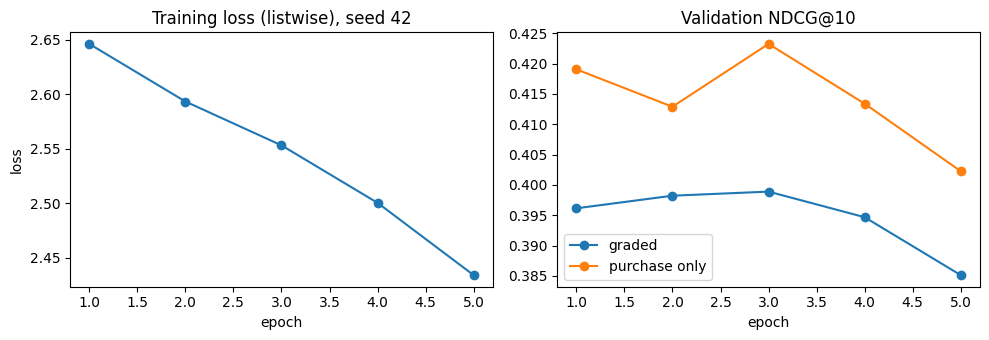

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(full_log["epoch"], full_log["train_loss"], marker="o")
ax[0].set(title="Training loss (listwise), seed 42", xlabel="epoch", ylabel="loss")
ax[1].plot(full_log["epoch"], full_log["val_ndcg@10"], marker="o", label="graded")
ax[1].plot(full_log["epoch"], full_log["val_ndcg@10_purchase"], marker="o", label="purchase only")
ax[1].set(title="Validation NDCG@10", xlabel="epoch")
ax[1].legend()
plt.tight_layout()
plt.savefig(OUT / "step3b_training_curve.png", dpi=150)
plt.show()

## 7. Ablations

Each variant removes one part of the full model and is trained with the same data, seeds and schedule:

| Variant | What changes | Question it answers |
|---|---|---|
| no match bias | Attention score is the dot product only; *m* is kept | Does biasing attention towards matching past actions help? |
| no match signals | No bias and no *m*: attention and scoring see matches only through the embeddings (the first version of this model, plus the query-relation embedding) | Do explicit match signals make the history useful at all? |
| no attribute match signals | Bias and *m* drop the four attribute matches (category, brand, shop); the query-relation signals stay | Is it matching on product attributes that makes the history useful? |
| no query match signals | Bias and *m* drop the history query relation; the attribute matches stay. The query-relation embedding in each past action is kept, as in "no match signals" | Do the explicit query-relation signals add anything beyond the query-relation embedding? |
| candidate-independent attention | Learned attention whose weights never see the candidate (as in the previous group's model); no match bias; *m* is still computed with these weights | Does conditioning the weights on the candidate help? |
| mean pooling | Every past action gets equal weight; *m* becomes the plain share of matching history | Does learned relevance beat a hand-built affinity count? |
| no action type | Type embedding removed, and type removed from the match bias | Does knowing click vs cart vs order matter? |
| no age | Age embedding removed | Does recency matter, given each type's window? |
| no history | History branch removed (candidate, query and dense features only) | What does reading the history add beyond workstream 1's history features? |
| no popularity | The 13 train-only popularity columns removed from the dense features | How much of the model's score comes from cross-user popularity? |
| no group history | The 15 brand, shop and category history columns removed from the dense features | How much do workstream 1's hand-built group features add? |
| with user features | The 17 user-level columns from workstream 1 added to the dense features | Do user-level features help this model? Step 3A dropped them after they lowered its test NDCG@10 (0.268 to 0.259, without popularity) |

Each ablation removes one *pathway*, not the information: "no action type" still has per-type truncation and type-specific dense features; "no age" still has dense recency features; "no history" still has workstream 1's product, brand, shop and category history features. A gap therefore measures what the pathway adds **on top of** the engineered features, and a null result does not by itself prove the signal is useless.

**Paired comparison.** For each session we average its NDCG@10 over the three seeds, then take the difference between the full model and the variant. The mean difference and its 95% confidence interval (±1.96 standard errors over sessions) say whether a gap is larger than session-to-session noise; it does not cover every source of uncertainty (for example other hyperparameter choices). A positive Δ means the full model is better.

**Validation first.** The first two runs of this notebook used test-set diagnostics to motivate design changes (Section 4), so the test set has been used for exploration. Ablation decisions are therefore read on the **validation** set, and the test intervals are reported alongside as confirmation.

In [20]:
ABLATIONS = {
    "candidate-independent attention": dict(pooling="independent", use_match=False),
    "no match bias": dict(use_match=False),
    "no match signals": dict(use_match=False, use_match_summary=False),
    "no attribute match signals": dict(match_groups=("query",)),
    "no query match signals": dict(match_groups=("attr",)),
    "mean pooling": dict(pooling="mean"),
    "no action type": dict(use_type=False),
    "no age": dict(use_age=False),
    "no history": dict(use_history=False),
}
ablation_models = {}
for name, config in ABLATIONS.items():
    ablation_models[name], _ = run(name, **config)

# these change the input columns, not a model switch, so each trains on its own columns of the matrix
main_dense, main_cols = cand_dense, DENSE_COLS
GROUP_COLS = GROUP_COUNTS + GROUP_DAYS
INPUT_ABLATIONS = {"no popularity": [c for c in main_cols if c not in pop_cols],
                   "no group history": [c for c in main_cols if c not in GROUP_COLS],
                   "with user features": all_cols}
assert [len(c) for c in INPUT_ABLATIONS.values()] == [36, 34, 66]
for name, cols in INPUT_ABLATIONS.items():
    cand_dense = all_dense if cols == all_cols else all_dense[:, [all_cols.index(c) for c in cols]]
    DENSE_COLS = cols
    ablation_models[name], _ = run(name)
    free_memory()
cand_dense, DENSE_COLS = main_dense, main_cols
del main_dense, main_cols


def seed_mean(name, col, split="test"):
    return pd.concat([session_ndcg[(name, s, split)][col] for s in SEEDS], axis=1).mean(axis=1)


paired = []
for name in list(ABLATIONS) + list(INPUT_ABLATIONS):
    row = {"variant": name}
    for split in ["val", "test"]:
        for col in ["graded", "purchase"]:
            d = (seed_mean(FULL, col, split) - seed_mean(name, col, split)).dropna()
            half = 1.96 * d.std() / np.sqrt(len(d))
            row[f"{split} Δ {col}"] = f"{d.mean():+.4f} [{d.mean() - half:+.4f}, {d.mean() + half:+.4f}]"
    paired.append(row)

display(seed_table("val"))
display(seed_table("test"))
pd.DataFrame(paired).set_index("variant")

[candidate-independent attention | seed 42] best epoch 2 of 4: val ndcg@10 0.3999 | 14s per epoch
[candidate-independent attention | seed 43] best epoch 2 of 4: val ndcg@10 0.3984 | 14s per epoch
[candidate-independent attention | seed 44] best epoch 2 of 4: val ndcg@10 0.4007 | 14s per epoch
[no match bias | seed 42] best epoch 3 of 5: val ndcg@10 0.3991 | 14s per epoch
[no match bias | seed 43] best epoch 1 of 3: val ndcg@10 0.3988 | 13s per epoch
[no match bias | seed 44] best epoch 2 of 4: val ndcg@10 0.4011 | 13s per epoch
[no match signals | seed 42] best epoch 2 of 4: val ndcg@10 0.3995 | 13s per epoch
[no match signals | seed 43] best epoch 1 of 3: val ndcg@10 0.3978 | 13s per epoch
[no match signals | seed 44] best epoch 2 of 4: val ndcg@10 0.4000 | 13s per epoch
[no attribute match signals | seed 42] best epoch 2 of 4: val ndcg@10 0.3991 | 15s per epoch
[no attribute match signals | seed 43] best epoch 1 of 3: val ndcg@10 0.3983 | 15s per epoch
[no attribute match signals | s

,ndcg@10,ndcg@10_purchase,hr@10,hr@10_purchase,mrr,seeds
model,,,,,,
attention (full),0.3990 ± 0.0012,0.4220 ± 0.0017,0.7044 ± 0.0019,0.6511 ± 0.0038,0.4061 ± 0.0015,3
candidate-independent attention,0.3997 ± 0.0011,0.4198 ± 0.0060,0.7042 ± 0.0024,0.6446 ± 0.0110,0.4077 ± 0.0017,3
mean pooling,0.3990 ± 0.0007,0.4209 ± 0.0035,0.7035 ± 0.0003,0.6470 ± 0.0059,0.4064 ± 0.0012,3
no action type,0.3994 ± 0.0010,0.4200 ± 0.0009,0.7052 ± 0.0010,0.6459 ± 0.0036,0.4069 ± 0.0015,3
no age,0.3992 ± 0.0012,0.4186 ± 0.0035,0.7049 ± 0.0023,0.6465 ± 0.0044,0.4065 ± 0.0006,3
no attribute match signals,0.3991 ± 0.0007,0.4198 ± 0.0004,0.7040 ± 0.0018,0.6481 ± 0.0029,0.4062 ± 0.0016,3
no group history,0.3967 ± 0.0009,0.4167 ± 0.0006,0.7007 ± 0.0007,0.6441 ± 0.0034,0.4033 ± 0.0016,3
no history,0.3990 ± 0.0007,0.4217 ± 0.0020,0.7041 ± 0.0021,0.6516 ± 0.0049,0.4061 ± 0.0012,3
no match bias,0.3997 ± 0.0013,0.4214 ± 0.0007,0.7055 ± 0.0012,0.6503 ± 0.0040,0.4069 ± 0.0011,3


,ndcg@10,ndcg@10_purchase,hr@10,hr@10_purchase,mrr,seeds
model,,,,,,
attention (full),0.3991 ± 0.0010,0.4100 ± 0.0016,0.6991 ± 0.0019,0.6373 ± 0.0038,0.4009 ± 0.0020,3
candidate-independent attention,0.3985 ± 0.0012,0.4117 ± 0.0004,0.6992 ± 0.0012,0.6389 ± 0.0024,0.4003 ± 0.0015,3
mean pooling,0.3985 ± 0.0005,0.4099 ± 0.0035,0.6999 ± 0.0001,0.6387 ± 0.0060,0.3998 ± 0.0011,3
no action type,0.3986 ± 0.0007,0.4108 ± 0.0004,0.7001 ± 0.0009,0.6413 ± 0.0033,0.3995 ± 0.0007,3
no age,0.3988 ± 0.0007,0.4108 ± 0.0030,0.7004 ± 0.0015,0.6395 ± 0.0011,0.3999 ± 0.0007,3
no attribute match signals,0.3989 ± 0.0002,0.4107 ± 0.0013,0.7006 ± 0.0006,0.6408 ± 0.0058,0.4000 ± 0.0007,3
no group history,0.3970 ± 0.0017,0.4086 ± 0.0008,0.6970 ± 0.0026,0.6367 ± 0.0030,0.3989 ± 0.0016,3
no history,0.3978 ± 0.0009,0.4117 ± 0.0022,0.6980 ± 0.0014,0.6406 ± 0.0053,0.3992 ± 0.0015,3
no match bias,0.3986 ± 0.0006,0.4099 ± 0.0018,0.6981 ± 0.0024,0.6380 ± 0.0036,0.4005 ± 0.0019,3


,val Δ graded,val Δ purchase,test Δ graded,test Δ purchase
variant,,,,
candidate-independent attention,"-0.0006 [-0.0016, +0.0003]","+0.0022 [-0.0007, +0.0052]","+0.0006 [-0.0003, +0.0015]","-0.0018 [-0.0047, +0.0011]"
no match bias,"-0.0006 [-0.0013, +0.0001]","+0.0006 [-0.0014, +0.0025]","+0.0005 [-0.0001, +0.0011]","+0.0000 [-0.0020, +0.0020]"
no match signals,"-0.0000 [-0.0009, +0.0008]","+0.0018 [-0.0011, +0.0046]","+0.0004 [-0.0004, +0.0013]","+0.0000 [-0.0028, +0.0029]"
no attribute match signals,"-0.0000 [-0.0009, +0.0009]","+0.0022 [-0.0007, +0.0051]","+0.0002 [-0.0007, +0.0011]","-0.0008 [-0.0036, +0.0021]"
no query match signals,"-0.0000 [-0.0010, +0.0009]","+0.0015 [-0.0015, +0.0044]","+0.0008 [-0.0001, +0.0017]","-0.0007 [-0.0036, +0.0022]"
mean pooling,"+0.0001 [-0.0007, +0.0009]","+0.0011 [-0.0014, +0.0037]","+0.0006 [-0.0002, +0.0013]","+0.0001 [-0.0024, +0.0025]"
no action type,"-0.0004 [-0.0012, +0.0004]","+0.0020 [-0.0005, +0.0046]","+0.0004 [-0.0003, +0.0012]","-0.0008 [-0.0032, +0.0015]"
no age,"-0.0002 [-0.0010, +0.0007]","+0.0034 [+0.0008, +0.0060]","+0.0003 [-0.0005, +0.0010]","-0.0008 [-0.0034, +0.0018]"
no history,"+0.0001 [-0.0008, +0.0010]","+0.0003 [-0.0026, +0.0033]","+0.0013 [+0.0004, +0.0021]","-0.0017 [-0.0046, +0.0012]"


## 8. What the Attention Reads

For every test candidate we record where the full model (seed 42) put its attention:

- **by action type**: weight on clicks, carts, orders, follows, and on the null slot ("nothing relevant");
- **by age**: weight on actions within about 1 hour, 1 day, 7 days, 90 days, and older (group edges follow the log2 age buckets, so each edge can be up to twice the stated age);
- **by match**: weight on past actions whose product shares the candidate's leaf category, level-3 category, brand or shop;
- **by query relation**: weight on actions whose past query contained some or all of today's query terms.

Attention percentages include the null slot, so the attention on history actions sums to 100% minus the null share, while the history shares sum to 100%. Both are averaged over the **same candidate rows** (each candidate carries its user's history shares), so a session with more candidates weighs the same in both. Attention is descriptive: a weight shows where the model looked, not how much that action moved the score; the ablations in Section 7 are the stronger evidence.

Comparing these with the share of each kind in the history (what equal weighting would give) shows what the model has learned to look for. Every group of candidates (ignored, clicked, carted, purchased; or engaged vs ignored) is compared with the history shares of **that same group**, since the users behind engaged candidates can have a different history mix from the users behind ignored ones. Section 8.1 then reads the learned match bias directly.

In [21]:
AGE_GROUPS = [("<= 1 hour", 3600), ("1 h - 1 day", 86400), ("1 - 7 days", 7 * 86400),
              ("7 - 90 days", 90 * 86400), ("> 90 days", 10 ** 9)]
age_edges = np.array([age_bucket(np.array([e]))[0] for _, e in AGE_GROUPS[:-1]])
QUERY_LEVELS = {1: "not from search", 2: "no shared term", 3: "some terms shared", 4: "all current terms"}
MATCH_NAMES = ["cate4", "cate3", "brand", "shop"]


@torch.no_grad()
def attention_summary(model, session_ids):
    model.eval()
    out = []
    for i in range(0, len(session_ids), EVAL_BATCH):
        batch, rows = make_batch(session_ids[i:i + EVAL_BATCH])
        score, attn = model(batch, return_attention=True)
        a_hist, a_null = attn[..., 1:], attn[..., 0]  # [B, C, L], [B, C]
        cols = {"score": score, "attn_null": a_null}
        for t, k in TYPE_IDX.items():
            cols[f"attn_{t.lower()}"] = (a_hist * (batch["hist_type"] == k).unsqueeze(1)).sum(-1)
        # age groups use bucket edges: bucket <= edge means age below the group's upper bound
        hb, lower = batch["hist_age"], 0
        for (gname, _), edge in zip(AGE_GROUPS, list(age_edges) + [N_AGE_BUCKETS]):
            cols[f"attn_age {gname}"] = (a_hist * ((hb > lower) & (hb <= edge)).unsqueeze(1)).sum(-1)
            lower = edge
        for lvl, gname in QUERY_LEVELS.items():
            cols[f"attn_query {gname}"] = (a_hist * (batch["hist_query"] == lvl).unsqueeze(1)).sum(-1)
        bits = match_bits(batch["hist_codes"], batch["cand_codes"]).float()  # [B, C, L, 4]
        n_hist = (batch["hist_type"] > 0).sum(-1).clamp(min=1).view(-1, 1, 1)
        attn_match = torch.einsum("bcl,bclk->bck", a_hist, bits)
        share_match = bits.sum(2) / n_hist
        for k, name in enumerate(MATCH_NAMES):
            cols[f"attn_same_{name}"] = attn_match[..., k]
            cols[f"share_same_{name}"] = share_match[..., k]
        valid = rows >= 0
        out.append(pd.DataFrame({k: v.float().cpu().numpy()[valid] for k, v in cols.items()}).assign(row=rows[valid]))
    df = pd.concat(out, ignore_index=True)
    df["session_id"], df["label"] = cand_session[df["row"]], cand_label[df["row"]]
    return df


attn_test = attention_summary(full_model, sessions["test"])

# what equal weighting would give: each user's history shares, attached to every candidate of that user,
# so the reference is averaged over exactly the same rows as the attention
test_ids = sessions["test"]
n_valid = (seq_type[test_ids] > 0).sum(1, keepdims=True).clip(min=1)
share = pd.DataFrame({f"attn_{t.lower()}": ((seq_type[test_ids] == k) / n_valid).sum(1) for t, k in TYPE_IDX.items()},
                     index=test_ids)
for lvl, g in QUERY_LEVELS.items():
    share[f"attn_query {g}"] = ((seq_query[test_ids] == lvl) / n_valid).sum(1)
ref = share.loc[attn_test["session_id"].to_numpy()].reset_index(drop=True)

label_names = {0: "ignored", 1: "click", 2: "cart", 3: "purchase"}
type_cols = [f"attn_{t.lower()}" for t in TYPES]
group = attn_test["label"].map(label_names).to_numpy()
att = attn_test.groupby(group)[["attn_null"] + type_cols].mean()
his = ref.groupby(group)[type_cols].mean()
by_label = pd.concat({"attention": att, "history share": his}, axis=1).reindex(list(label_names.values()))
by_label = by_label.rename(columns=lambda c: c.replace("attn_", "") + " (%)", level=1)
display((by_label * 100).round(1))

age_cols = [c for c in attn_test.columns if c.startswith("attn_age")]
by_age = attn_test.groupby(attn_test["label"] > 0)[age_cols].mean().mul(100).round(1)
by_age.index = ["ignored", "engaged"]
display(by_age.rename(columns=lambda c: c.replace("attn_age ", "") + " (%)"))

query_cols = [f"attn_query {g}" for g in QUERY_LEVELS.values()]
by_query = attn_test.groupby(attn_test["label"] > 0)[query_cols].mean()
by_query.index = ["ignored", "engaged"]
ref_query = ref.groupby(attn_test["label"].to_numpy() > 0)[query_cols].mean()
by_query.loc["history share: ignored"] = ref_query.loc[False].to_numpy()
by_query.loc["history share: engaged"] = ref_query.loc[True].to_numpy()
display((by_query * 100).round(1).rename(columns=lambda c: c.replace("attn_query ", "") + " (%)"))

ign_rows, eng_rows = attn_test["label"] == 0, attn_test["label"] > 0
match = pd.DataFrame({
    "attention, ignored (%)": [attn_test.loc[ign_rows, f"attn_same_{n}"].mean() * 100 for n in MATCH_NAMES],
    "share, ignored (%)": [attn_test.loc[ign_rows, f"share_same_{n}"].mean() * 100 for n in MATCH_NAMES],
    "attention, engaged (%)": [attn_test.loc[eng_rows, f"attn_same_{n}"].mean() * 100 for n in MATCH_NAMES],
    "share, engaged (%)": [attn_test.loc[eng_rows, f"share_same_{n}"].mean() * 100 for n in MATCH_NAMES],
    "attention, all (%)": [attn_test[f"attn_same_{n}"].mean() * 100 for n in MATCH_NAMES],
    "share of history (%)": [attn_test[f"share_same_{n}"].mean() * 100 for n in MATCH_NAMES],
}, index=["same leaf category", "same level-3 category", "same brand", "same shop"])
match["lift (attention / share)"] = match["attention, all (%)"] / match["share of history (%)"]
match.round(2)

attention                                          history share                         
           null (%)  click (%)   cart (%)    ord (%) flw (%)     click (%) cart (%) ord (%) flw (%)
ignored   28.700001  27.400000  23.299999  20.500000     0.1          30.5     40.1    29.3     0.0
click     28.900000  29.299999  22.400000  19.299999     0.1          32.3     39.2    28.4     0.0
cart      26.400000  27.799999  24.299999  21.400000     0.1          28.9     42.0    28.9     0.1
purchase  27.000000  22.299999  22.900000  27.799999     0.0          25.0     37.9    37.0     0.0

,<= 1 hour (%),1 h - 1 day (%),1 - 7 days (%),7 - 90 days (%),> 90 days (%)
ignored,14.9,7.9,12.3,27.1,9.1
engaged,15.7,8.4,12.3,26.5,9.0


,not from search (%),no shared term (%),some terms shared (%),all current terms (%)
ignored,41.3,18.6,10.4,1.0
engaged,41.0,18.0,11.7,1.0
history share: ignored,59.4,36.6,3.7,0.3
history share: engaged,59.3,36.1,4.3,0.3


,"attention, ignored (%)","share, ignored (%)","attention, engaged (%)","share, engaged (%)","attention, all (%)",share of history (%),lift (attention / share)
same leaf category,8.60,5.99,11.40,7.82,8.66,6.02,1.44
same level-3 category,9.19,6.43,11.94,8.25,9.25,6.47,1.43
same brand,3.86,2.79,5.58,3.83,3.90,2.81,1.39
same shop,0.76,0.53,2.85,1.85,0.80,0.56,1.44


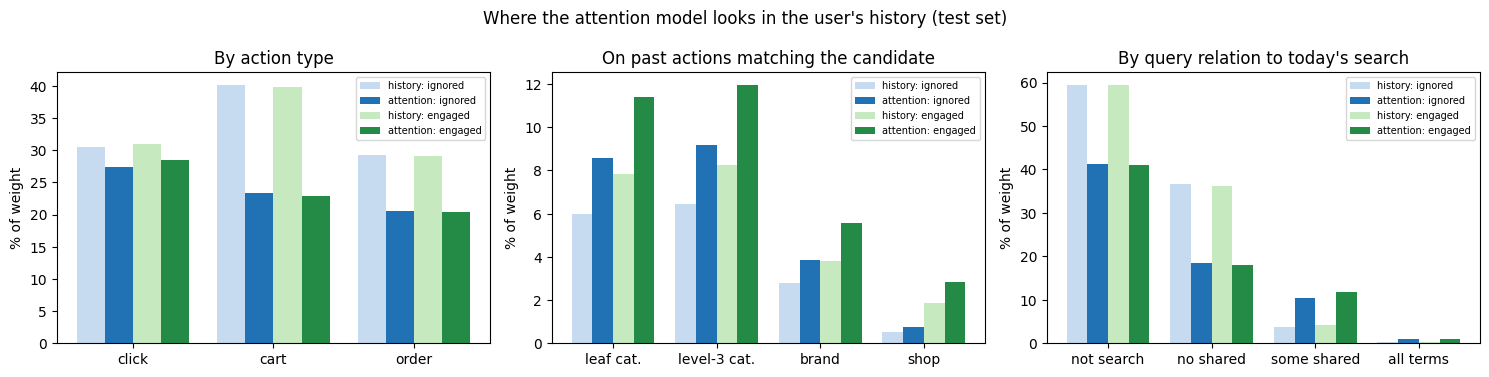

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
# each group of candidates is drawn next to the history shares of the same group
styles = [("history: ignored", "#c6dbef"), ("attention: ignored", "#2171b5"),
          ("history: engaged", "#c7e9c0"), ("attention: engaged", "#238b45")]


def grouped_bars(axis, series, ticks, title):
    x = np.arange(len(ticks))
    for k, ((lab, color), vals) in enumerate(zip(styles, series)):
        axis.bar(x + (k - 1.5) * 0.2, np.asarray(vals) * 100, width=0.2, label=lab, color=color)
    axis.set_xticks(x, ticks)
    axis.set(ylabel="% of weight", title=title)
    axis.legend(fontsize=7)


plot_types = [f"attn_{t.lower()}" for t in ["CLICK", "CART", "ORD"]]
eng_ref, ign_ref = ref[eng_rows.to_numpy()], ref[ign_rows.to_numpy()]
grouped_bars(ax[0], [ign_ref[plot_types].mean(), attn_test.loc[ign_rows, plot_types].mean(),
                     eng_ref[plot_types].mean(), attn_test.loc[eng_rows, plot_types].mean()],
             ["click", "cart", "order"], "By action type")
grouped_bars(ax[1], [match["share, ignored (%)"] / 100, match["attention, ignored (%)"] / 100,
                     match["share, engaged (%)"] / 100, match["attention, engaged (%)"] / 100],
             ["leaf cat.", "level-3 cat.", "brand", "shop"], "On past actions matching the candidate")
grouped_bars(ax[2], [by_query.loc["history share: ignored"], by_query.loc["ignored"],
                     by_query.loc["history share: engaged"], by_query.loc["engaged"]],
             ["not search", "no shared", "some shared", "all terms"], "By query relation to today's search")
fig.suptitle("Where the attention model looks in the user's history (test set)")
plt.tight_layout()
plt.savefig(OUT / "step3b_attention_weights.png", dpi=150)
plt.show()

### 8.1 The Learned Match Bias

The match bias *b*[type, query relation, match pattern] is added to the attention score of a past action. The null slot gets no bias (its score is the candidate's projection dotted with a learned null key), so a positive bias pulls weight towards that action relative to the null slot and to other actions. The table shows the learned values for actions not taken from search, for each action type and a ladder of increasingly close matches.

In [23]:
patterns = {"no match": 0, "level-3 category only": 2, "same leaf category": 3,
            "leaf category + brand": 7, "leaf category + brand + shop": 15}
bias = full_model.match_bias.weight.detach().cpu().numpy().ravel()
table = {}
for t, k in TYPE_IDX.items():
    if t == "FLW":
        continue
    for lvl in [1, 4]:
        table[(t.lower(), QUERY_LEVELS[lvl])] = {name: bias[(k * N_QUERY_LEVELS + lvl) * 16 + p] for name, p in patterns.items()}
pd.DataFrame(table).T.round(2)

no match  level-3 category only  same leaf category  leaf category + brand  leaf category + brand + shop
click not from search       -0.11                   0.09                0.00                   0.12                          0.03
      all current terms     -0.06                  -0.01                0.10                   0.03                         -0.02
cart  not from search       -0.11                  -0.02                0.03                   0.01                          0.13
      all current terms     -0.06                  -0.05                0.07                   0.10                         -0.01
ord   not from search        0.03                  -0.04                0.00                   0.01                         -0.04
      all current terms     -0.04                   0.05                0.04                   0.11                         -0.02

### 8.2 Where Reading the History Helps

Test NDCG@10 of the full model against the no-history variant (each averaged over the three seeds per session), split by the length of the user's truncated history and by whether the search continues an ongoing session. The segments show where the history helps; they are not a test of any one mechanism. Workstream 6 (diagnostics) extends this to other segments.

In [24]:
seg = pd.DataFrame({"full": seed_mean(FULL, "graded"), "no history": seed_mean("no history", "graded")})
seg["history length"] = pd.cut(seq_len[seg.index], [0, 10, 50, 120, SEQ_LEN], include_lowest=True,
                               labels=["1-10", "11-50", "51-120", "121-160"])
seg["in session"] = user_feats.set_index("session_id").loc[seg.index, "in_session"].map({1: "continuing", 0: "new visit"}).to_numpy()
has_seen = cand.groupby("session_id")["prod_seen_before"].max()
seg["repeat candidate"] = has_seen.loc[seg.index].map({1: "slate has a product seen before", 0: "no product seen before"}).to_numpy()
for by in ["history length", "in session", "repeat candidate"]:
    g = seg.assign(d=seg["full"] - seg["no history"]).groupby(by, observed=True)
    t = g.agg(sessions=("full", "size"), full=("full", "mean"), no_history=("no history", "mean"), gain=("d", "mean"))
    t["gain 95% CI ±"] = 1.96 * g["d"].std() / np.sqrt(g.size())
    display(t.round(4))

,sessions,full,no_history,gain,gain 95% CI ±
history length,,,,,
1-10,1355,0.3712,0.3689,0.0023,0.0026
11-50,3612,0.3917,0.3916,0.0001,0.0016
51-120,5231,0.4016,0.4001,0.0015,0.0014
121-160,2682,0.4180,0.4162,0.0019,0.0019


,sessions,full,no_history,gain,gain 95% CI ±
in session,,,,,
continuing,5317,0.4198,0.4177,0.0021,0.0014
new visit,7563,0.3845,0.3838,0.0007,0.0011


,sessions,full,no_history,gain,gain 95% CI ±
repeat candidate,,,,,
no product seen before,9212,0.3642,0.3631,0.0011,0.0011
slate has a product seen before,3668,0.4865,0.4849,0.0016,0.0015


## 9. Exports for Step 4 and the Results Table

- `step3b_test_scores.parquet`: one row per test candidate with keys (`session_id`, `candidate_pos`, `wid`), `label`, and the seed-42 score of the full model and of each ablation. Workstream 6 joins these for segment diagnostics.
- `step3b_popularity_features.parquet`: the 13 train-only popularity features per search and product (`session_id`, `wid`), written in Section 3 and read by step 3A.
- `step3b_attention_summary.parquet`: per test candidate, the full model's attention weight by action type, age group, query relation and attribute match (Section 8).
- `step3b_results.csv`: every (model, seed, split) row with all metrics, for the team's shared results table.
- `step3b_session_ndcg.parquet`: per-session NDCG@10 (graded and purchase) for every model, seed and split (val, test), so the paired intervals can be recomputed.
- `step3b_model.pt`: the full model (seed 42) with its preprocessing metadata (vocabularies, dense-feature order, normalisation, caps).
- `step3b_run_manifest.json`: when and how the run was made (device, seeds, epochs, models), peak RAM of the kernel, row counts and file sizes. It is written last, so a folder without it holds an unfinished run.

In [25]:
rows = test_scores[FULL].index.to_numpy()
export = cand.loc[rows, ["session_id", "candidate_pos", "wid", "label"]].reset_index(drop=True)
for name, s in test_scores.items():
    export["score_" + name.replace("attention (full)", "full").replace(" ", "_")] = s.loc[rows].to_numpy()
export.to_parquet(OUT / "step3b_test_scores.parquet", index=False)

attn_export = attn_test.drop(columns=["label", "session_id"]).merge(
    cand[["session_id", "candidate_pos", "wid", "label"]], left_on="row", right_index=True).drop(columns="row")
attn_export.to_parquet(OUT / "step3b_attention_summary.parquet", index=False)

res = pd.DataFrame(results)
res.to_csv(OUT / "step3b_results.csv", index=False)
per_session = pd.concat([df.assign(model=m, seed=s, split=sp).rename_axis("session_id").reset_index()
                         for (m, s, sp), df in session_ndcg.items()], ignore_index=True)
per_session.to_parquet(OUT / "step3b_session_ndcg.parquet", index=False)
print(f"test scores: {len(export):,} rows | attention summary: {len(attn_export):,} rows | "
      f"per-session metrics: {len(per_session):,} rows")

import resource
import sys

# peak resident memory of this kernel so far (macOS reports bytes, linux kilobytes); gpu memory is not included
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (2 ** 30 if sys.platform == "darwin" else 2 ** 20)
files = ["product_lookup.parquet", "step3b_popularity_features.parquet", "step3b_test_scores.parquet", "step3b_attention_summary.parquet", "step3b_results.csv",
         "step3b_session_ndcg.parquet", "step3b_model.pt", "step3b_training_curve.png", "step3b_attention_weights.png"]
manifest = {
    "finished": pd.Timestamp.now().isoformat(timespec="seconds"),
    "dev_run": DEV, "device": str(DEVICE), "peak_ram_gb": round(peak, 2), "seeds": SEEDS, "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "negatives": N_NEG,
    "models": [FULL] + list(ABLATIONS) + list(INPUT_ABLATIONS),
    "sessions": {s: len(sessions[s]) for s in ["train", "val", "test"]},
    "rows": {"results": len(res), "test_scores": len(export), "attention_summary": len(attn_export), "session_ndcg": len(per_session)},
    "file_bytes": {f: (OUT / f).stat().st_size for f in files},
}
(OUT / "step3b_run_manifest.json").write_text(json.dumps(manifest, indent=1))

summary = res.groupby(["model", "split"])[["ndcg@10", "ndcg@10_purchase", "mrr"]].mean().unstack("split")
summary = summary.reindex(columns=["train", "val", "test"], level=1)
summary.round(4)

test scores: 1,147,673 rows | attention summary: 1,147,673 rows | per-session metrics: 1,004,640 rows


ndcg@10                 ndcg@10_purchase                     mrr                
split                             train     val    test            train     val    test   train     val    test
model                                                                                                           
attention (full)                 0.4065  0.3990  0.3991           0.4182  0.4220  0.4100  0.4099  0.4061  0.4009
candidate-independent attention  0.4047  0.3997  0.3985           0.4169  0.4198  0.4117  0.4087  0.4077  0.4003
mean pooling                     0.4020  0.3990  0.3985           0.4147  0.4209  0.4099  0.4058  0.4064  0.3998
no action type                   0.4022  0.3994  0.3986           0.4145  0.4200  0.4108  0.4060  0.4069  0.3995
no age                           0.4022  0.3992  0.3988           0.4154  0.4186  0.4108  0.4060  0.4065  0.3999
no attribute match signals       0.4022  0.3991  0.3989           0.4140  0.4198  0.4107  0.4061  0.4062  0.4000
no group history                 0.4004  0.3967  0.3970           0.4134  0.4167  0.4086  0.4045  0.4033  0.3989
no history                       0.4013  0.3990  0.3978           0.4144  0.4217  0.4117  0.4050  0.4061  0.3992
no match bias                    0.4066  0.3997  0.3986           0.4189  0.4214  0.4099  0.4099  0.4069  0.4005
no match signals                 0.4022  0.3991  0.3986           0.4149  0.4202  0.4099  0.4063  0.4063  0.4000
no popularity                    0.3723  0.2790  0.2768           0.3686  0.2794  0.2690  0.3694  0.2937  0.2886
no query match signals           0.4044  0.3991  0.3983           0.4170  0.4205  0.4107  0.4081  0.4066  0.3998
reference: BM25 only                NaN     NaN  0.0900              NaN     NaN  0.0718     NaN     NaN  0.1071
reference: popularity only          NaN     NaN  0.3282              NaN     NaN  0.3329     NaN     NaN  0.3254
reference: random                   NaN     NaN  0.0837              NaN     NaN  0.0676     NaN     NaN  0.1013
with user features               0.4095  0.3992  0.3989           0.4222  0.4194  0.4120  0.4125  0.4063  0.4011

## 10. Summary of Results

Validation and test sets: 12,880 searches each (test: 1,147,673 candidates), full slates; train metrics on all 60,104 training searches, also on full slates; three seeds per variant (mean ± sd). Δ is the full model minus the variant, paired over sessions after averaging the three seeds, with a 95% confidence interval; validation is the decision set (the test set was used for exploration in earlier runs), test confirms. History actions logged within 1 s of the search are dropped (section 2.2). The dense features are the same 49 as step 3A's final model.

| Model | Test NDCG@10 | Test purchase NDCG@10 | Val Δ NDCG@10 [95% CI] | Test Δ NDCG@10 [95% CI] |
|---|---|---|---|---|
| Random order | 0.0837 | 0.0676 | | |
| BM25 only | 0.0900 | 0.0718 | | |
| Popularity only | 0.3282 | 0.3329 | | |
| **Attention model (full)** | **0.3991 ± 0.0010** | **0.4100 ± 0.0016** | | |
| no popularity | 0.2768 ± 0.0009 | 0.2690 ± 0.0005 | +0.1200 [+0.1155, +0.1245] | +0.1222 [+0.1176, +0.1269] |
| no group history | 0.3970 ± 0.0017 | 0.4086 ± 0.0008 | +0.0023 [+0.0011, +0.0036] | +0.0020 [+0.0008, +0.0033] |
| no history branch | 0.3978 ± 0.0009 | 0.4117 ± 0.0022 | +0.0001 [−0.0008, +0.0010] | +0.0013 [+0.0004, +0.0021] |
| mean pooling | 0.3985 ± 0.0005 | 0.4099 ± 0.0035 | +0.0001 [−0.0007, +0.0009] | +0.0006 [−0.0002, +0.0013] |
| no query match signals | 0.3983 ± 0.0015 | 0.4107 ± 0.0011 | 0.0000 [−0.0010, +0.0009] | +0.0008 [−0.0001, +0.0017] |
| no match signals | 0.3986 ± 0.0006 | 0.4099 ± 0.0009 | 0.0000 [−0.0009, +0.0008] | +0.0004 [−0.0004, +0.0013] |
| no attribute match signals | 0.3989 ± 0.0002 | 0.4107 ± 0.0013 | 0.0000 [−0.0009, +0.0009] | +0.0002 [−0.0007, +0.0011] |
| no age | 0.3988 ± 0.0007 | 0.4108 ± 0.0030 | −0.0002 [−0.0010, +0.0007] | +0.0003 [−0.0005, +0.0010] |
| with user features | 0.3989 ± 0.0008 | 0.4120 ± 0.0013 | −0.0002 [−0.0012, +0.0008] | +0.0001 [−0.0008, +0.0011] |
| no action type | 0.3986 ± 0.0007 | 0.4108 ± 0.0004 | −0.0004 [−0.0012, +0.0004] | +0.0004 [−0.0003, +0.0012] |
| no match bias | 0.3986 ± 0.0006 | 0.4099 ± 0.0018 | −0.0006 [−0.0013, +0.0001] | +0.0005 [−0.0001, +0.0011] |
| candidate-independent attention | 0.3985 ± 0.0012 | 0.4117 ± 0.0004 | −0.0006 [−0.0016, +0.0003] | +0.0006 [−0.0003, +0.0015] |

- The full model beats popularity alone by +0.071 NDCG@10. Train / validation / test NDCG@10 are 0.407 / 0.399 / 0.399. The train figure varies by seed (sd 0.010) because the seeds stop at different epochs.
- Popularity is the largest single input. Without the 13 popularity features, test NDCG@10 falls by 0.122 to 0.2768, below popularity alone.
- The 15 brand, shop and category features add +0.0023 on validation and +0.0020 on test. Adding the 17 user-level features back changes nothing measurable.
- **Reading the past actions adds nothing measurable on validation** (+0.0001 [−0.0008, +0.0010]). The test interval excludes zero (+0.0013 [+0.0004, +0.0021]), but validation does not confirm it and the same code on a Mac gives +0.0008 [−0.0001, +0.0018] on test, so it is not claimed. Attribute and query match signals, learned weighting, candidate-specific weights, action type and age also add nothing measurable on validation.
- **The ablations do not separate why.** The dense features already summarise each user's past actions on the same product, brand, shop and category, so overlap with them is a likely reason the branch adds little.
- Purchase NDCG@10 shows no gain from the branch (validation +0.0003 [−0.0026, +0.0033], test −0.0017 [−0.0046, +0.0012]). On validation, the 15 features (+0.0053 [+0.0010, +0.0096]) and the age embedding (+0.0034 [+0.0008, +0.0060]) raise it, neither confirmed on test.
- This Colab run matches the Mac run of the same code (full model: validation −0.0002 [−0.0011, +0.0007], test +0.0004 [−0.0004, +0.0013]) with identical reference scores, but attention moved: same-leaf-category actions get 1.44× their share of the history here and 1.23× on the Mac, and the null slot 26-29% and 24-28%. Treat attention percentages as approximate.
- Attention favours past actions that match the candidate (same leaf category 1.44×, brand 1.39×, shop 1.44×, all above 1 on both machines). Engaged and ignored candidates get about the same multiplier (1.46× and 1.44× for leaf category): engaged products simply have more matching history. Given the ablations, these weights describe what the model reads, not a source of ranking gain.
- The gain from the branch does not differ reliably between visit types. Continuing visits: test +0.0021 ± 0.0014, validation +0.0013 ± 0.0014. New visits: test +0.0007 ± 0.0011, validation −0.0008 ± 0.0012. Earlier versions of the model showed a gain only in continuing visits; that claim does not hold on these inputs.
- Against step 3A's LambdaRank on the same 49 features (test NDCG@10 0.4059, validation 0.4072), LambdaRank is ahead by +0.0071 [+0.0047, +0.0096] on test, paired with this notebook's seed-42 model using the two notebooks' test predictions. The train-test gap is 0.007 here against 0.037 for LambdaRank. The one difference in inputs is missing query-product values (up to 5.9% of test rows per column), which LightGBM keeps as missing and this model sets to 0. LambdaRank's figure is one tuned fit, and this model's is three seeds without tuning for this comparison.